## Credit Pre-Screening Engine — Loan Intake Optimisation

## Problem Statement

The bank's lending unit faces challenges in reviewing a large volume of loan applications manually, resulting in increased analyst workload, delays in decision-making, and inconsistent assessments. The objective of this project is to develop a machine-learning-based loan application pre-screener that predicts the likelihood of an application being declined and categorizes applications into three lanes: fast-track approval, human review, and potential automated decline. The goal is to reduce manual review effort and improve operational efficiency while keeping incorrect automated decisions below 5% in each automated lane, with appropriate human oversight and fairness monitoring.

#  CBIM Problem Canvas

| **Canvas Element** | **Your Answer** |
|---|---|
| **Situation (S)** | The bank's lending unit receives loan applications from applicants with different income levels, credit histories, employment types, and repayment commitments. Analysts manually review applications to decide whether to approve or decline them, requiring time and effort to assess individual cases. |
| **Complication (C)** | Manual review of every application can increase analysts' workload, delay decisions, and affect the customer experience. Inconsistent assessments may also affect decision quality, while applicants may experience unnecessary delays or unfair outcomes. |
| **Question (Q)** | How can the bank use a machine-learning pre-screener to identify applications for fast-track approval, human review, or potential automated decline while keeping incorrect automated decisions within an acceptable limit? |
| **SSOT (Single Source of Truth)** | The cleaned loan application dataset, represented by `df_clean`, is the source of truth for this analysis. The `decision` column contains historical outcomes: `Approved` and `Declined`. For modelling, these are encoded as `0 = Approved` and `1 = Declined`. These labels represent past decisions and do not guarantee future repayment outcomes. |
| **Success Definition** | The primary success criterion is an incorrect-decision rate of no more than **5% in each automated decision lane**: fast-track approval and automated decline. Additional metrics include ROC-AUC, precision, recall, accuracy, and fairness across applicant groups. The current Gradient Boosting test results meet this provisional target, but the thresholds require independent validation before deployment. |
| **Primary Stakeholder** | The primary stakeholder is the head of lending or credit operations, who must balance decision speed, analyst workload, lending risk, and customer experience. Other affected stakeholders include credit analysts, loan applicants, risk and compliance teams, and senior management. |


## Part 1 — Baseline Pre-Screener
### 5.1  Load, inspect and clean


In [1]:
import pandas as pd
import numpy as np

In [2]:
df = pd.read_csv("C:\Calibo\Mini_usecase2\MUC02_Credit_PreScreening_Dataset.csv")
df

<>:1: SyntaxWarning: invalid escape sequence '\C'
<>:1: SyntaxWarning: invalid escape sequence '\C'
C:\Users\KEERTHI\AppData\Local\Temp\ipykernel_1324\2737299470.py:1: SyntaxWarning: invalid escape sequence '\C'
  df = pd.read_csv("C:\Calibo\Mini_usecase2\MUC02_Credit_PreScreening_Dataset.csv")


,application_id,application_date,age,gender,city,city_tier,employment_type,years_in_current_job,monthly_income,existing_emi,credit_score,credit_history_months,num_active_loans,delinquencies_24m,loan_purpose,loan_amount,tenure_months,proposed_emi,decision
0,APP100001,2026-04-01,28,Male,Hyderabad,1,Salaried,4.1,95000.0,23500.0,784.0,109,2,0,Home Renovation,240000.0,48,6600.0,Approved
1,APP100002,2026-04-01,36,Female,Raipur,3,Business Owner,0.6,43000.0,8500.0,790.0,162,2,0,Wedding,145000.0,36,5000.0,Approved
2,APP100003,2026-04-01,35,Male,Nagpur,2,Salaried,4.4,35000.0,3500.0,718.0,151,1,1,Medical,345000.0,36,11800.0,Approved
3,APP100004,2026-04-01,42,Male,Jaipur,2,Salaried,5.8,44500.0,0.0,NaN,0,0,0,Travel,135000.0,36,4600.0,Approved
4,APP100005,2026-04-01,34,Male,Kochi,2,Self-Employed Professional,2.1,83500.0,6000.0,700.0,127,1,3,Medical,700000.0,24,33600.0,Declined
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
11995,APP111996,2026-09-30,34,Male,Guntur,3,Salaried,3.8,24000.0,3000.0,684.0,111,1,0,Debt Consolidation,190000.0,36,6500.0,Declined
11996,APP111997,2026-09-30,42,Male,Indore,2,Salaried,3.2,87500.0,43500.0,743.0,204,5,1,Travel,550000.0,48,15000.0,Declined
11997,APP111998,2026-09-30,40,Male,Nagpur,2,Salaried,6.7,57500.0,5500.0,666.0,179,1,1,Medical,510000.0,48,13900.0,Approved
11998,APP111999,2026-09-30,37,Female,Nashik,3,Salaried,2.4,30500.0,3500.0,685.0,150,1,0,Consumer Durables,85000.0,36,2900.0,Approved


In [3]:
df.head()

,application_id,application_date,age,gender,city,city_tier,employment_type,years_in_current_job,monthly_income,existing_emi,credit_score,credit_history_months,num_active_loans,delinquencies_24m,loan_purpose,loan_amount,tenure_months,proposed_emi,decision
0,APP100001,2026-04-01,28,Male,Hyderabad,1,Salaried,4.1,95000.0,23500.0,784.0,109,2,0,Home Renovation,240000.0,48,6600.0,Approved
1,APP100002,2026-04-01,36,Female,Raipur,3,Business Owner,0.6,43000.0,8500.0,790.0,162,2,0,Wedding,145000.0,36,5000.0,Approved
2,APP100003,2026-04-01,35,Male,Nagpur,2,Salaried,4.4,35000.0,3500.0,718.0,151,1,1,Medical,345000.0,36,11800.0,Approved
3,APP100004,2026-04-01,42,Male,Jaipur,2,Salaried,5.8,44500.0,0.0,NaN,0,0,0,Travel,135000.0,36,4600.0,Approved
4,APP100005,2026-04-01,34,Male,Kochi,2,Self-Employed Professional,2.1,83500.0,6000.0,700.0,127,1,3,Medical,700000.0,24,33600.0,Declined


In [4]:
df.shape

(12000, 19)

In [5]:
df.columns

Index(['application_id', 'application_date', 'age', 'gender', 'city',
       'city_tier', 'employment_type', 'years_in_current_job',
       'monthly_income', 'existing_emi', 'credit_score',
       'credit_history_months', 'num_active_loans', 'delinquencies_24m',
       'loan_purpose', 'loan_amount', 'tenure_months', 'proposed_emi',
       'decision'],
      dtype='str')

In [6]:
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 12000 entries, 0 to 11999
Data columns (total 19 columns):
 #   Column                 Non-Null Count  Dtype  
---  ------                 --------------  -----  
 0   application_id         12000 non-null  str    
 1   application_date       12000 non-null  str    
 2   age                    12000 non-null  int64  
 3   gender                 12000 non-null  str    
 4   city                   12000 non-null  str    
 5   city_tier              12000 non-null  int64  
 6   employment_type        12000 non-null  str    
 7   years_in_current_job   12000 non-null  float64
 8   monthly_income         11559 non-null  float64
 9   existing_emi           12000 non-null  float64
 10  credit_score           10961 non-null  float64
 11  credit_history_months  12000 non-null  int64  
 12  num_active_loans       12000 non-null  int64  
 13  delinquencies_24m      12000 non-null  int64  
 14  loan_purpose           12000 non-null  str    
 15  loan_amount  

In [7]:
df.describe()

,age,city_tier,years_in_current_job,monthly_income,existing_emi,credit_score,credit_history_months,num_active_loans,delinquencies_24m,loan_amount,tenure_months,proposed_emi
count,12000.000000,12000.000000,12000.000000,1.155900e+04,12000.000000,10961.000000,12000.000000,12000.000000,12000.000000,1.200000e+04,12000.000000,12000.00000
mean,33.153750,1.707917,3.774850,6.031486e+04,6273.166667,725.920080,114.880167,1.166000,0.775750,3.795925e+05,37.726000,15067.10000
std,7.058878,0.757728,3.149578,4.889083e+04,8526.169300,62.559023,77.329483,1.148356,1.227024,2.950731e+05,15.077131,15160.83502
min,21.000000,1.000000,0.000000,1.200000e+04,0.000000,479.000000,0.000000,0.000000,0.000000,5.000000e+04,12.000000,1200.00000
25%,28.000000,1.000000,1.500000,3.350000e+04,0.000000,684.000000,54.000000,0.000000,0.000000,1.750000e+05,24.000000,6000.00000
50%,33.000000,2.000000,3.000000,5.050000e+04,4000.000000,726.000000,114.000000,1.000000,0.000000,3.000000e+05,36.000000,10600.00000
75%,38.000000,2.000000,5.100000,7.475000e+04,8500.000000,769.000000,169.000000,2.000000,1.000000,4.900000e+05,48.000000,18700.00000
max,60.000000,3.000000,30.000000,1.656000e+06,96500.000000,890.000000,395.000000,8.000000,11.000000,2.500000e+06,60.000000,224500.00000


In [8]:
df.isnull().sum()

application_id              0
application_date            0
age                         0
gender                      0
city                        0
city_tier                   0
employment_type             0
years_in_current_job        0
monthly_income            441
existing_emi                0
credit_score             1039
credit_history_months       0
num_active_loans            0
delinquencies_24m           0
loan_purpose                0
loan_amount                 0
tenure_months               0
proposed_emi                0
decision                    0
dtype: int64

In [9]:
##Calculate the overall approval rate

decision_counts = df["decision"].value_counts()
print("Decision counts:")
print(decision_counts)

decision_percentages = df["decision"].value_counts(normalize=True) * 100
print("\nDecision percentages:")
print(decision_percentages.round(2))

approval_rate = (df["decision"] == "Approved").mean() * 100
print("\nOverall approval rate:", round(approval_rate, 2), "%")

Decision counts:
decision
Approved    6353
Declined    5647
Name: count, dtype: int64

Decision percentages:
decision
Approved    52.94
Declined    47.06
Name: proportion, dtype: float64

Overall approval rate: 52.94 %


In [10]:
missing_income = df[df["monthly_income"].isnull()]

print("Missing income count by employment type:")
print(missing_income["employment_type"].value_counts())

print("\nPercentage of missing income within each employment type:")
print(
    (df.groupby("employment_type")["monthly_income"]
       .apply(lambda x: x.isnull().mean() * 100))
    .round(2)
)

Missing income count by employment type:
employment_type
Business Owner                227
Self-Employed Professional    154
Salaried                       49
Gig / Contract                 11
Name: count, dtype: int64

Percentage of missing income within each employment type:
employment_type
Business Owner                12.98
Gig / Contract                 0.62
Salaried                       0.69
Self-Employed Professional    10.78
Name: monthly_income, dtype: float64


In [11]:
missing_score = df[df["credit_score"].isnull()]

print("Number of missing credit scores:", len(missing_score))

print("\nCredit history for applicants with missing scores:")
print(missing_score["credit_history_months"].value_counts(dropna=False))

Number of missing credit scores: 1039

Credit history for applicants with missing scores:
credit_history_months
0    1039
Name: count, dtype: int64


In [12]:
print("Maximum monthly income:", df["monthly_income"].max())

high_income = df[df["monthly_income"] > 400000]

print("\nNumber of records with income above ₹4,00,000:")
print(len(high_income))

print("\nHigh-income records:")
print(
    high_income[
        ["application_id", "employment_type", "monthly_income"]
    ].sort_values("monthly_income", ascending=False)
)

Maximum monthly income: 1656000.0

Number of records with income above ₹4,00,000:
17

High-income records:
     application_id employment_type  monthly_income
1467      APP101468        Salaried       1656000.0
300       APP100301        Salaried       1254000.0
2493      APP102494        Salaried       1212000.0
589       APP100590        Salaried       1068000.0
9849      APP109850        Salaried        990000.0
1848      APP101849        Salaried        984000.0
2488      APP102489        Salaried        972000.0
4010      APP104011        Salaried        900000.0
4898      APP104899        Salaried        870000.0
9261      APP109262        Salaried        702000.0
7426      APP107427        Salaried        690000.0
8381      APP108382        Salaried        618000.0
595       APP100596        Salaried        546000.0
6909      APP106910        Salaried        444000.0
1984      APP101985        Salaried        438000.0
7983      APP107984        Salaried        432000.0
9388     

In [13]:
# Create a copy of the original dataset
df_clean = df.copy()

In [14]:
# Identify unusually high monthly income values
high_income_mask = df_clean["monthly_income"] > 400000


In [15]:
# Correct these values using the annual-to-monthly assumption
df_clean.loc[high_income_mask, "monthly_income"] = (
    df_clean.loc[high_income_mask, "monthly_income"] / 12
)

In [16]:
# Fill missing income using the median of each employment type
employment_median = df_clean.groupby(
    "employment_type"
)["monthly_income"].transform("median")

df_clean["monthly_income"] = df_clean["monthly_income"].fillna(
    employment_median
)

print("Original dataset shape:", df.shape)
print("Cleaned dataset shape:", df_clean.shape)

print("\nMissing values after cleaning:")
print(df_clean.isnull().sum())

Original dataset shape: (12000, 19)
Cleaned dataset shape: (12000, 19)

Missing values after cleaning:
application_id              0
application_date            0
age                         0
gender                      0
city                        0
city_tier                   0
employment_type             0
years_in_current_job        0
monthly_income              0
existing_emi                0
credit_score             1039
credit_history_months       0
num_active_loans            0
delinquencies_24m           0
loan_purpose                0
loan_amount                 0
tenure_months               0
proposed_emi                0
decision                    0
dtype: int64


In [17]:
print("Missing monthly income:", df_clean["monthly_income"].isnull().sum())

print("Missing credit scores:", df_clean["credit_score"].isnull().sum())

print("Total rows:", df_clean.shape[0])

print("Total columns:", df_clean.shape[1])

print("\nCredit history of applicants with missing credit scores:")
print(
    df_clean.loc[
        df_clean["credit_score"].isnull(),
        "credit_history_months"
    ].value_counts()
)

Missing monthly income: 0
Missing credit scores: 1039
Total rows: 12000
Total columns: 19

Credit history of applicants with missing credit scores:
credit_history_months
0    1039
Name: count, dtype: int64


## 5.1 — Data Loading, Cleaning and Initial Inspection

### Key Findings
- The dataset contains **12,000 rows and 19 columns**.
- There are 6,353 approved applications (52.94%) and 5,647 declined applications (47.06%).
- There are 1,039 missing credit scores. All applicants with missing credit scores have zero recorded credit history months.
- Missing monthly income was identified mainly among Business Owners (227 records) and Self-Employed Professionals (154 records).
- Seventeen records have monthly income above ₹4,00,000 and require verification.

### Data Cleaning
- Missing monthly income values were handled, leaving no missing income values after cleaning.
- Missing credit scores were retained for further processing because they may indicate applicants with no recorded credit history.
- The cleaned dataset contains 12,000 rows and 19 columns.

### Conclusion
The dataset is nearly balanced between approved and declined applications. Missing credit scores and unusually high income values require careful consideration during feature engineering and modelling.

## Step 5.2 — What Drives Approval Today?

In [18]:
import matplotlib.pyplot as plt
import seaborn as sns

In [19]:
score_bins = [0, 599, 649, 699, 749, 799, float("inf")]

score_labels = [
    "Below 600",
    "600-649",
    "650-699",
    "700-749",
    "750-799",
    "800+"
]

df_clean["credit_score_band"] = pd.cut(
    df_clean["credit_score"],
    bins=score_bins,
    labels=score_labels
)

df_clean["credit_score_band"] = (
    df_clean["credit_score_band"]
    .astype("object")
    .fillna("No score")
)

print(df_clean["credit_score_band"].value_counts())

credit_score_band
700-749      3377
650-699      2529
750-799      2526
800+         1350
No score     1039
600-649       933
Below 600     246
Name: count, dtype: int64


In [20]:
approval_by_score = (
    df_clean.assign(
        approved=df_clean["decision"].eq("Approved")
    )
    .groupby("credit_score_band", observed=False)["approved"]
    .mean()
    .mul(100)
    .reindex(score_labels + ["No score"])
)

print("Approval rate by credit score band:")
print(approval_by_score.round(2))

Approval rate by credit score band:
credit_score_band
Below 600     2.03
600-649       3.22
650-699      32.50
700-749      54.37
750-799      77.20
800+         85.19
No score     53.90
Name: approved, dtype: float64


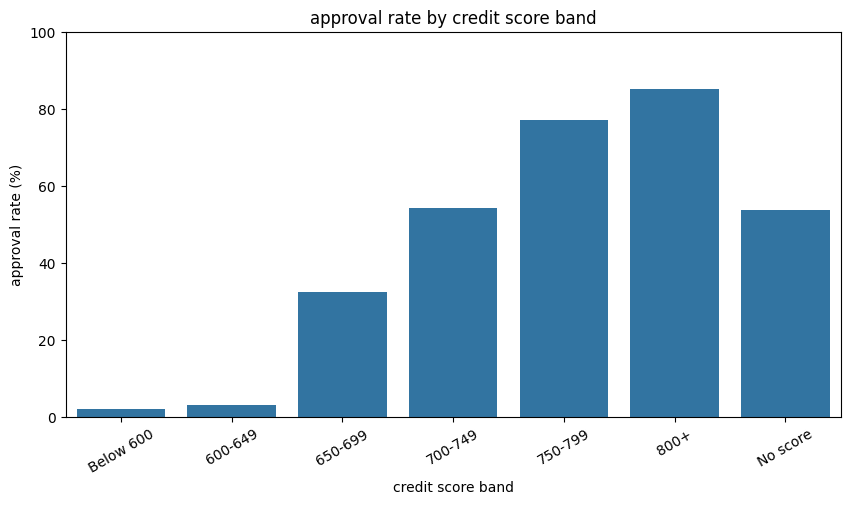

In [21]:
plt.figure(figsize=(10, 5))

sns.barplot(
    x=approval_by_score.index,
    y=approval_by_score.values
)

plt.title("approval rate by credit score band")
plt.xlabel("credit score band")
plt.ylabel("approval rate (%)")
plt.xticks(rotation=30)
plt.ylim(0, 100)

plt.show()

In [22]:
approval_by_employment = (
    df_clean.assign(
        approved=df_clean["decision"].eq("Approved")
    )
    .groupby("employment_type")["approved"]
    .mean()
    .mul(100)
    .sort_values(ascending=False)
)

print("approval rate by employment type:")
print(approval_by_employment.round(2))

approval rate by employment type:
employment_type
Salaried                      58.37
Business Owner                51.17
Self-Employed Professional    50.56
Gig / Contract                34.94
Name: approved, dtype: float64


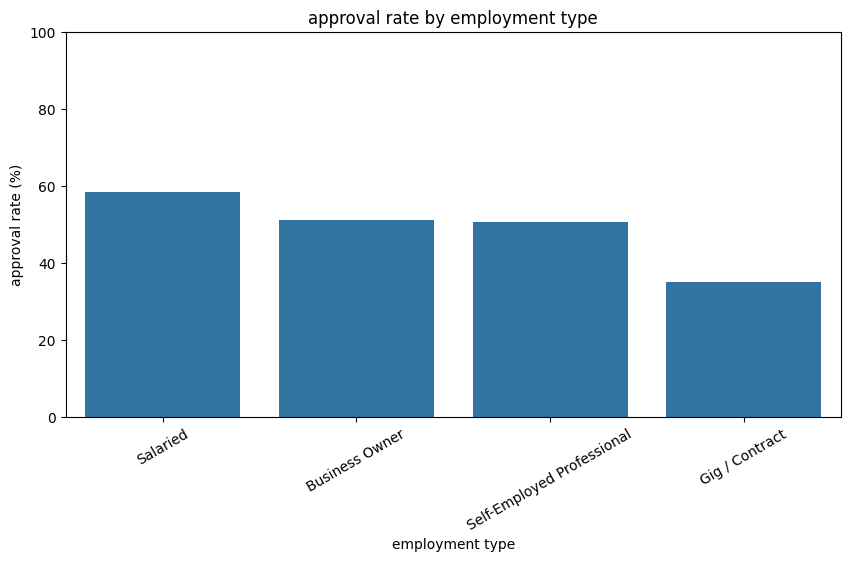

In [23]:
plt.figure(figsize=(10, 5))

sns.barplot(
    x=approval_by_employment.index,
    y=approval_by_employment.values
)

plt.title("approval rate by employment type")
plt.xlabel("employment type")
plt.ylabel("approval rate (%)")
plt.xticks(rotation=30)
plt.ylim(0, 100)

plt.show()

In [24]:
no_score_rate = (
    df_clean.loc[
        df_clean["credit_score"].isnull(), "decision"
    ].eq("Approved").mean() * 100
)

scored_rate = (
    df_clean.loc[
        df_clean["credit_score"].notnull(), "decision"
    ].eq("Approved").mean() * 100
)

below_600_rate = (
    df_clean.loc[
        df_clean["credit_score"] < 600, "decision"
    ].eq("Approved").mean() * 100
)

print("approval rate for applicants with no score:",
      round(no_score_rate, 2), "%")

print("approval rate for applicants with a score:",
      round(scored_rate, 2), "%")

print("approval rate for applicants below 600:",
      round(below_600_rate, 2), "%")

approval rate for applicants with no score: 53.9 %
approval rate for applicants with a score: 52.85 %
approval rate for applicants below 600: 2.03 %


## 5.2 Findings: What Drives Approval Today?

1. Credit score and approval

The approval rate for applicants with a credit score below 600 is only **2.03%**. This means that almost all applicants in this group were declined.

This suggests that the bank follows a strong unwritten credit policy of rarely approving applicants with very low credit scores. A score below 600 may act as a practical warning threshold in the bank's historical decision-making process. However, this does not prove that the bank has a formal rule that automatically rejects every applicant below 600.

2. Applicants with no credit score

The approval rate for applicants with no recorded credit score is 53.90%, compared with 52.85% for applicants with a recorded credit score.

Applicants without a credit score have a slightly higher approval rate, by 1.05 percentage points. This suggests that the bank does not automatically reject applicants simply because their credit score is missing.

Since these applicants have zero months of credit history, they may be new-to-credit customers. Their missing scores should therefore not be treated as poor credit scores.

3. Employment type and approval

The approval rates by employment type should be compared using the employment chart. Differences between groups may reflect the bank's historical lending practices and how it evaluates applicants with different employment arrangements. We should examine these differences alongside credit score, income, and existing loan obligations rather than assuming that employment type alone determines approval.

Conclusion

Credit score appears to be an important factor in historical loan decisions because the approval rate below 600 is only 2.03%. Applicants without a recorded credit score have an approval rate of 53.90%, which is slightly higher than the 52.85% rate among scored applicants.

These findings suggest that a very low credit score and a missing credit score are treated differently in the historical data. The bank should avoid treating new-to-credit applicants as automatically high-risk simply because they lack a recorded score. These observations will guide the next stages of feature engineering and model development.

## 5.3  Engineer the affordability feature 

FOIR stands for Fixed Obligation to Income Ratio. It measures how much of an applicant's monthly income is used to pay existing loan EMIs and the proposed loan EMI.

We calculate FOIR by adding existing EMI and proposed EMI, then dividing the total by monthly income. A higher FOIR means that a larger share of the applicant's income is committed to loan repayments.

We keep FOIR as a ratio for calculations. For example, a FOIR of 0.40 represents 40% of monthly income.

In [25]:
### Create the FOIR Feature

df_clean["foir"] = (
    (df_clean["existing_emi"] + df_clean["proposed_emi"])
    / df_clean["monthly_income"]
)

df_clean[["existing_emi", "proposed_emi", "monthly_income", "foir"]].head()

,existing_emi,proposed_emi,monthly_income,foir
0,23500.0,6600.0,95000.0,0.316842
1,8500.0,5000.0,43000.0,0.313953
2,3500.0,11800.0,35000.0,0.437143
3,0.0,4600.0,44500.0,0.103371
4,6000.0,33600.0,83500.0,0.474251


In [26]:
## Create the Loan-to-Income Feature

df_clean["loan_to_income"] = (
    df_clean["loan_amount"]
    / (df_clean["monthly_income"] * 12)
)

df_clean[["loan_amount", "monthly_income", "loan_to_income"]].head()

,loan_amount,monthly_income,loan_to_income
0,240000.0,95000.0,0.210526
1,145000.0,43000.0,0.281008
2,345000.0,35000.0,0.821429
3,135000.0,44500.0,0.252809
4,700000.0,83500.0,0.698603


In [27]:
##Create the is_ntc feature

df_clean["is_ntc"] = (
    df_clean["credit_score"].isnull().astype(int)
)

df_clean[["credit_score", "credit_history_months", "is_ntc"]].head()

,credit_score,credit_history_months,is_ntc
0,784.0,109,0
1,790.0,162,0
2,718.0,151,0
3,NaN,0,1
4,700.0,127,0


In [28]:
df_clean["is_ntc"].value_counts()

is_ntc
0    10961
1     1039
Name: count, dtype: int64

In [29]:
###  Check the New Features

df_clean[["foir", "loan_to_income"]].describe()

,foir,loan_to_income
count,12000.000000,12000.000000
mean,0.358329,0.531339
std,0.207059,0.225194
min,0.004798,0.014731
25%,0.214706,0.347222
50%,0.316667,0.519097
75%,0.450048,0.699405
max,3.393333,2.777778


In [30]:
## Group Applicants by FOIR

conditions = [
    df_clean["foir"] < 0.30,
    (df_clean["foir"] >= 0.30) & (df_clean["foir"] < 0.40),
    (df_clean["foir"] >= 0.40) & (df_clean["foir"] < 0.50),
    (df_clean["foir"] >= 0.50) & (df_clean["foir"] <= 0.55),
    df_clean["foir"] > 0.55
]

foir_labels = [
    "Below 30%",
    "30-40%",
    "40-50%",
    "50-55%",
    "Above 55%"
]

df_clean["foir_band"] = np.select(
    conditions,
    foir_labels,
    default="Check FOIR"
)

print(df_clean["foir_band"].value_counts())

foir_band
Below 30%    5488
30-40%       2499
40-50%       1767
Above 55%    1711
50-55%        535
Name: count, dtype: int64


In [31]:
## Calculate approval rate by FOIR band

foir_order = [
    "Below 30%",
    "30-40%",
    "40-50%",
    "50-55%",
    "Above 55%"
]

approval_by_foir = (
    df_clean.assign(
        approved=df_clean["decision"].eq("Approved")
    )
    .groupby("foir_band")["approved"]
    .mean()
    .mul(100)
    .reindex(foir_order)
)

print("Approval rate by FOIR band:")
print(approval_by_foir.round(2))

Approval rate by FOIR band:
foir_band
Below 30%    65.49
30-40%       58.98
40-50%       47.82
50-55%       32.52
Above 55%    15.55
Name: approved, dtype: float64


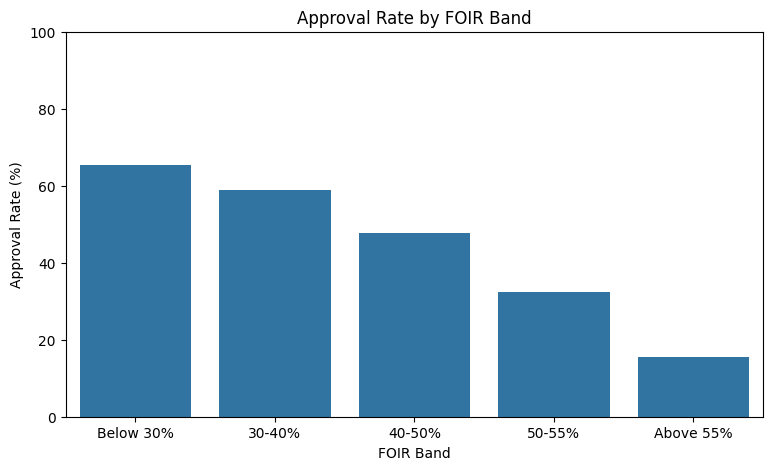

In [32]:
### Plot approval rate by FOIR band

plt.figure(figsize=(9, 5))

sns.barplot(
    x=approval_by_foir.index,
    y=approval_by_foir.values
)

plt.title("Approval Rate by FOIR Band")
plt.xlabel("FOIR Band")
plt.ylabel("Approval Rate (%)")
plt.ylim(0, 100)

plt.show()

## 5.3 Findings: FOIR and Loan Affordability

1. FOIR and approval rate

FOIR measures the percentage of an applicant's monthly income used to pay existing and proposed loan EMIs. The approval rates across the five FOIR bands are:

- Below 30%: 65.49%
- **30–40%:** 58.98%
- **40–50%:** 47.82%
- **50–55%:** 32.52%
- **Above 55%:** 15.55%

The chart shows that approval rates decrease as FOIR increases. The decline becomes particularly noticeable above 40% FOIR. The approval rate falls from 47.82% in the 40–50% band to 32.52% in the 50–55% band, a decrease of 15.30 percentage points.

For applicants with FOIR above 55%, the approval rate falls further to 15.55%. This suggests that applicants with a higher repayment burden are less likely to be approved.

**2. Proposed FOIR policy limit**

Based on these results, I would propose a preliminary FOIR limit of **40% for further testing**. Applicants with FOIR at or below 40% have higher historical approval rates than applicants in the higher FOIR bands.

Applications above 40% FOIR could receive additional affordability checks. However, FOIR alone should not automatically determine approval or rejection. The final limit should be validated against repayment outcomes, affordability risk, and the bank's credit policy requirements.

**3. Conclusion**

The analysis shows a clear negative relationship between FOIR and historical loan approval rates. As FOIR increases, the approval rate decreases, with a particularly noticeable drop in the higher FOIR bands.

The new `foir`, `loan_to_income`, and `is_ntc` features will help the baseline pre-screener assess repayment burden, loan size relative to annual income, and new-to-credit status. These features will be used in the next stages of the project to investigate approval patterns and build predictive models.

## 5.4  Build the logistic regression pre-screener

In [33]:
import pandas as pd
import numpy as np

from sklearn.model_selection import train_test_split
from sklearn.compose import ColumnTransformer
from sklearn.preprocessing import StandardScaler, OneHotEncoder
from sklearn.impute import SimpleImputer
from sklearn.pipeline import Pipeline
from sklearn.linear_model import LogisticRegression

from sklearn.metrics import (
    accuracy_score,
    confusion_matrix,
    classification_report,
    precision_score,
    recall_score
)

In [34]:
y = (df_clean["decision"] == "Declined").astype(int)

print("Target counts:")
print(y.value_counts())

print("\nTarget percentages:")
print((y.value_counts(normalize=True) * 100).round(2))

Target counts:
decision
0    6353
1    5647
Name: count, dtype: int64

Target percentages:
decision
0    52.94
1    47.06
Name: proportion, dtype: float64


In [35]:
## Select the Model Features

numeric_features = [
    "credit_score",
    "is_ntc",
    "foir",
    "loan_to_income",
    "delinquencies_24m",
    "num_active_loans",
    "years_in_current_job",
    "age",
    "tenure_months",
    "city_tier"
]

categorical_features = [
    "employment_type",
    "loan_purpose"
]

feature_columns = numeric_features + categorical_features

X = df_clean[feature_columns].copy()

print("Feature dataset shape:", X.shape)
print("\nSelected features:")
print(X.columns.tolist())

Feature dataset shape: (12000, 12)

Selected features:
['credit_score', 'is_ntc', 'foir', 'loan_to_income', 'delinquencies_24m', 'num_active_loans', 'years_in_current_job', 'age', 'tenure_months', 'city_tier', 'employment_type', 'loan_purpose']


In [36]:
## Check missing credit scores

print("Missing credit scores before imputation:")
print(X["credit_score"].isnull().sum())

print("\nMedian credit score:")
print(X["credit_score"].median())

Missing credit scores before imputation:
1039

Median credit score:
726.0


In [37]:
##  Split the Dataset into Training and Testing Sets

X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.20,
    stratify=y,
    random_state=42
)

print("Training feature shape:", X_train.shape)
print("Testing feature shape:", X_test.shape)

print("\nTraining target distribution:")
print(y_train.value_counts())

print("\nTesting target distribution:")
print(y_test.value_counts())

Training feature shape: (9600, 12)
Testing feature shape: (2400, 12)

Training target distribution:
decision
0    5082
1    4518
Name: count, dtype: int64

Testing target distribution:
decision
0    1271
1    1129
Name: count, dtype: int64


In [38]:
### Prepare Numerical and Categorical Features

numeric_pipeline = Pipeline(steps=[
    ("imputer", SimpleImputer(strategy="median")),
    ("scaler", StandardScaler())
])

categorical_pipeline = Pipeline(steps=[
    ("imputer", SimpleImputer(strategy="most_frequent")),
    ("encoder", OneHotEncoder(handle_unknown="ignore"))
])

preprocessor = ColumnTransformer(
    transformers=[
        ("numeric", numeric_pipeline, numeric_features),
        ("categorical", categorical_pipeline, categorical_features)
    ]
)

In [39]:
## Build and train the Logistic Regression model

logistic_model = Pipeline(steps=[
    ("preprocessor", preprocessor),
    ("classifier", LogisticRegression(max_iter=1000))
])

logistic_model.fit(X_train, y_train)

print("Logistic Regression model trained successfully.")

Logistic Regression model trained successfully.


In [40]:
## Predict declined applications

y_pred = logistic_model.predict(X_test)

print("First 20 actual decisions:")
print(y_test.iloc[:20].to_list())

print("\nFirst 20 predicted decisions:")
print(y_pred[:20].tolist())

First 20 actual decisions:
[0, 1, 0, 1, 0, 0, 1, 1, 1, 0, 0, 1, 1, 1, 0, 0, 0, 1, 0, 1]

First 20 predicted decisions:
[0, 1, 0, 1, 0, 0, 1, 0, 1, 1, 0, 0, 1, 1, 0, 0, 0, 0, 0, 1]


In [41]:
## Evaluate Model Accuracy

accuracy = accuracy_score(y_test, y_pred)

print("Model accuracy:", round(accuracy * 100, 2), "%")

Model accuracy: 79.08 %


In [42]:
cm = confusion_matrix(y_test, y_pred, labels=[0, 1])

cm_df = pd.DataFrame(
    cm,
    index=["Actual Approved", "Actual Declined"],
    columns=["Predicted Approved", "Predicted Declined"]
)

print(cm_df)

                 Predicted Approved  Predicted Declined
Actual Approved                1046                 225
Actual Declined                 277                 852


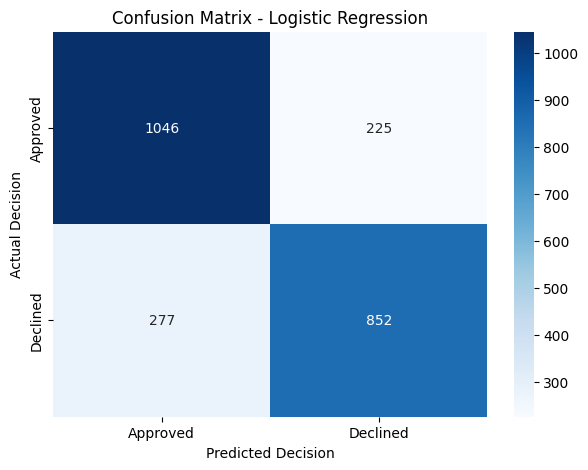

In [43]:
plt.figure(figsize=(7, 5))

sns.heatmap(
    cm,
    annot=True,
    fmt="d",
    cmap="Blues",
    xticklabels=["Approved", "Declined"],
    yticklabels=["Approved", "Declined"]
)

plt.title("Confusion Matrix - Logistic Regression")
plt.xlabel("Predicted Decision")
plt.ylabel("Actual Decision")

plt.show()

In [44]:
## Calculate Precision and Recall for Declined Applications

declined_precision = precision_score(
    y_test, y_pred, pos_label=1, zero_division=0
)

declined_recall = recall_score(
    y_test, y_pred, pos_label=1, zero_division=0
)

print("Precision for Declined:", round(declined_precision, 4))
print("Recall for Declined:", round(declined_recall, 4))

print("\nFull classification report:")
print(
    classification_report(
        y_test,
        y_pred,
        labels=[0, 1],
        target_names=["Approved", "Declined"],
        zero_division=0
    )
)

Precision for Declined: 0.7911
Recall for Declined: 0.7547

Full classification report:
              precision    recall  f1-score   support

    Approved       0.79      0.82      0.81      1271
    Declined       0.79      0.75      0.77      1129

    accuracy                           0.79      2400
   macro avg       0.79      0.79      0.79      2400
weighted avg       0.79      0.79      0.79      2400



In [45]:
### Identify the Five Largest Logistic Regression Coefficients

fitted_preprocessor = logistic_model.named_steps["preprocessor"]
fitted_classifier = logistic_model.named_steps["classifier"]

feature_names = fitted_preprocessor.get_feature_names_out()
coefficients = fitted_classifier.coef_[0]

coefficient_table = pd.DataFrame({
    "feature": feature_names,
    "coefficient": coefficients
})

coefficient_table["direction"] = np.where(
    coefficient_table["coefficient"] > 0,
    "Pushes towards Declined",
    "Pushes towards Approved"
)

top_5_features = (
    coefficient_table
    .assign(abs_coefficient=lambda x: x["coefficient"].abs())
    .sort_values("abs_coefficient", ascending=False)
    .head(5)
)

print("Top 5 features by absolute coefficient:")
print(
    top_5_features[
        ["feature", "coefficient", "direction"]
    ].to_string(index=False)
)

Top 5 features by absolute coefficient:
                                    feature  coefficient               direction
                              numeric__foir     1.221619 Pushes towards Declined
                      numeric__credit_score    -1.009297 Pushes towards Approved
                 numeric__delinquencies_24m     0.978398 Pushes towards Declined
categorical__employment_type_Gig / Contract     0.619425 Pushes towards Declined
      categorical__employment_type_Salaried    -0.445238 Pushes towards Approved


## 5.4 Findings: Logistic Regression Pre-Screener

**1. Model performance**

The Logistic Regression model achieved an accuracy of **79.08%** on the test dataset of 2,400 applications. This means the model correctly predicted the historical decision for approximately 79 out of every 100 applications.

The precision for the Declined class was **79.11%**, and the recall was **75.47%**.

- **Precision of 79.11%:** Of all applications predicted as declined, approximately 79% were actually declined by the credit team.
- **Recall of 75.47%:** The model correctly identified approximately 75% of all applications that were historically declined.

**2. Confusion matrix and business impact**

The confusion matrix produced the following results:

| Actual / Predicted | Predicted Approved | Predicted Declined |
|---|---:|---:|
| Actual Approved | 1,046 | 225 |
| Actual Declined | 277 | 852 |

The model correctly predicted 1,046 approved applications and 852 declined applications.

However, **225 historically approved applications were incorrectly predicted as declined**. If the model were used to automatically reject these applications, these applicants could be wrongly screened out.

The model also predicted 277 historically declined applications as approved. These cases would need further review because the model did not identify them as declines.

These results show why the model should support credit analysts rather than automatically make final lending decisions. A historical approval does not guarantee that an applicant is creditworthy, and a historical decline does not prove that the applicant would default.

**3. Top five features influencing the model**

The five features with the largest absolute coefficients were:

| Feature | Coefficient | Direction |
|---|---:|---|
| FOIR | +1.222 | Pushes towards Declined |
| Credit score | -1.009 | Pushes towards Approved |
| Delinquencies in the last 24 months | +0.978 | Pushes towards Declined |
| Gig / Contract employment | +0.619 | Pushes towards Declined |
| Salaried employment | -0.445 | Pushes towards Approved |

FOIR has the largest absolute coefficient. This indicates that a higher FOIR is strongly associated with predictions towards Declined, holding the other model inputs constant.

Credit score has a negative coefficient, meaning that a higher score is associated with predictions towards Approved. Delinquencies in the previous 24 months have a positive coefficient, meaning that more delinquencies are associated with predictions towards Declined.

Gig / Contract employment has a positive coefficient relative to the reference employment category, while Salaried employment has a negative coefficient relative to that category. These results describe associations learned from historical decisions; they do not prove that employment type causes a loan decision.

**4. Conclusion**

The baseline Logistic Regression model achieved 79.08% accuracy, with 79.11% precision and 75.47% recall for the Declined class.

The confusion matrix shows that 225 historically approved applications were incorrectly flagged as declined. This is an important business risk if predictions are used for pre-screening.

FOIR, credit score, recent delinquencies, and employment-type indicators were among the strongest model coefficients. These findings provide an initial understanding of the historical decision patterns and will help guide model comparison and threshold selection in the next stages.

Before using the model in practice, the bank should assess fairness, validate performance on appropriate data, and evaluate the consequences of wrongly screening out applicants.


## 5.5  Set the auto-decline threshold

In [46]:
# Get predicted probabilities for the test dataset
y_proba = logistic_model.predict_proba(X_test)[:, 1]

print("First 10 decline probabilities:")
print(np.round(y_proba[:10], 4))

First 10 decline probabilities:
[0.1465 0.8097 0.3663 0.8072 0.1451 0.4836 0.8777 0.115  0.7931 0.9284]


In [47]:
## Create the threshold comparison table

thresholds = [0.5, 0.6, 0.7, 0.8, 0.85, 0.9, 0.95]

threshold_results = []

for threshold in thresholds:

    # Applications with decline probability at or above threshold
    auto_decline = y_proba >= threshold

    # Total number of auto-declined applications
    auto_declined_count = auto_decline.sum()

    # Percentage of all test applications auto-declined
    auto_decline_rate = auto_decline.mean() * 100

    # Of auto-declined applications, how many were actually approved?
    if auto_declined_count > 0:
        wrongly_declined_count = (
            (y_test.to_numpy() == 0) & auto_decline
        ).sum()

        wrong_decline_rate = (
            wrongly_declined_count / auto_declined_count
        ) * 100
    else:
        wrongly_declined_count = 0
        wrong_decline_rate = np.nan

    threshold_results.append({
        "Threshold": threshold,
        "Auto-Declined Count": auto_declined_count,
        "Auto-Decline Rate (%)": auto_decline_rate,
        "Wrongly Declined Count": wrongly_declined_count,
        "Wrong-Decline Rate (%)": wrong_decline_rate
    })

threshold_table = pd.DataFrame(threshold_results)

print(threshold_table.round(2).to_string(index=False))

 Threshold  Auto-Declined Count  Auto-Decline Rate (%)  Wrongly Declined Count  Wrong-Decline Rate (%)
      0.50                 1077                  44.88                     225                   20.89
      0.60                  902                  37.58                     152                   16.85
      0.70                  738                  30.75                      89                   12.06
      0.80                  563                  23.46                      40                    7.10
      0.85                  472                  19.67                      28                    5.93
      0.90                  365                  15.21                      17                    4.66
      0.95                  239                   9.96                       5                    2.09


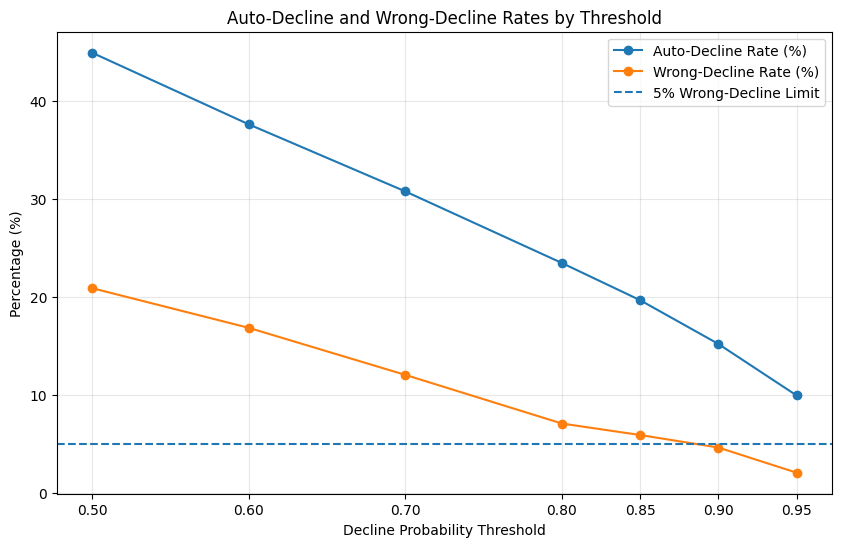

In [48]:
## Plot both rates on one chart

plt.figure(figsize=(10, 6))

plt.plot(
    threshold_table["Threshold"],
    threshold_table["Auto-Decline Rate (%)"],
    marker="o",
    label="Auto-Decline Rate (%)"
)

plt.plot(
    threshold_table["Threshold"],
    threshold_table["Wrong-Decline Rate (%)"],
    marker="o",
    label="Wrong-Decline Rate (%)"
)

plt.axhline(
    y=5,
    linestyle="--",
    label="5% Wrong-Decline Limit"
)

plt.title("Auto-Decline and Wrong-Decline Rates by Threshold")
plt.xlabel("Decline Probability Threshold")
plt.ylabel("Percentage (%)")
plt.xticks(thresholds)
plt.grid(True, alpha=0.3)
plt.legend()

plt.show()

In [49]:
## Select the threshold that meets the bank's risk rule

eligible_thresholds = threshold_table[
    threshold_table["Wrong-Decline Rate (%)"] <= 5
]

if not eligible_thresholds.empty:
    best_threshold_row = eligible_thresholds.loc[
        eligible_thresholds["Auto-Decline Rate (%)"].idxmax()
    ]

    best_threshold = best_threshold_row["Threshold"]

    print("Selected threshold:", best_threshold)
    print(
        "Auto-decline rate (%):",
        round(best_threshold_row["Auto-Decline Rate (%)"], 2)
    )
    print(
        "Wrong-decline rate (%):",
        round(best_threshold_row["Wrong-Decline Rate (%)"], 2)
    )
    print(
        "Applications auto-declined in test set:",
        int(best_threshold_row["Auto-Declined Count"])
    )

else:
    best_threshold = None
    best_threshold_row = None

    print("No tested threshold meets the 5% wrong-decline rule.")

Selected threshold: 0.9
Auto-decline rate (%): 15.21
Wrong-decline rate (%): 4.66
Applications auto-declined in test set: 365


In [50]:
##Calculate the monthly business impact

monthly_applications = 3000
minutes_per_review = 25


    

In [51]:

if best_threshold is not None and best_threshold_row is not None:

    monthly_applications = 3000
    minutes_per_review = 25

    auto_decline_rate = (
        best_threshold_row["Auto-Decline Rate (%)"] / 100
    )

    monthly_auto_declines = monthly_applications * auto_decline_rate

    monthly_hours_saved = (
        monthly_auto_declines * minutes_per_review / 60
    )

    print(
        "Selected threshold:",
        best_threshold
    )

    print(
        "Estimated applications auto-declined per month:",
        round(monthly_auto_declines)
    )

    print(
        "Estimated analyst hours saved per month:",
        round(monthly_hours_saved, 2)
    )

else:
    print(
        "Choose a threshold that meets the risk rule before "
        "estimating monthly savings."
    )


Selected threshold: 0.9
Estimated applications auto-declined per month: 456
Estimated analyst hours saved per month: 190.1


## 5.5: Selecting the Auto-Decline Threshold

The selected threshold is **0.90**, because it gives the highest auto-decline rate among the tested thresholds that satisfy the maximum 5% wrong-decline-rate requirement.

At this threshold, the model has an auto-decline rate of **15.21%** and a wrong-decline rate of **4.66%** on the test data. It automatically declined 365 applications in the test set.

Assuming 3,000 applications per month and 25 minutes of manual review per application, the estimated operational benefit is approximately **456 applications auto-declined and 190.1 analyst hours saved per month**.

These estimates are based on historical test results. The threshold should be validated further, and automatic declines should not be implemented without appropriate risk, fairness, compliance, and human-review safeguards.

## 5.6  Fairness check

In [52]:

# Create an indicator for historical approvals
df_clean["approved_flag"] = (
    df_clean["decision"] == "Approved"
).astype(int)

# Calculate approval rate and application count by gender
approval_by_gender = (
    df_clean.groupby("gender")["approved_flag"]
    .agg(["mean", "count"])
    .reset_index()
)

approval_by_gender["Approval Rate (%)"] = (
    approval_by_gender["mean"] * 100
).round(2)

approval_by_gender = approval_by_gender.rename(
    columns={"count": "Applications"}
)

approval_by_gender = approval_by_gender[
    ["gender", "Applications", "Approval Rate (%)"]
]

display(approval_by_gender)


,gender,Applications,Approval Rate (%)
0,Female,3795,50.43
1,Male,8205,54.10


In [53]:

approval_by_gender_employment = pd.pivot_table(
    df_clean,
    index="employment_type",
    columns="gender",
    values="approved_flag",
    aggfunc="mean"
) * 100

approval_by_gender_employment = (
    approval_by_gender_employment.round(2)
)

print("Historical approval rate (%) by employment type and gender:")
display(approval_by_gender_employment)


Historical approval rate (%) by employment type and gender:


gender,Female,Male
employment_type,,
Business Owner,51.62,51.05
Gig / Contract,34.65,35.18
Salaried,56.79,59.06
Self-Employed Professional,47.63,51.97


In [54]:

# Median monthly income by gender
median_income = (
    df_clean.groupby("gender")["monthly_income"]
    .median()
    .rename("Median Monthly Income")
)

# Share of applicants in Gig / Contract employment by gender
gig_share = (
    df_clean.assign(
        is_gig_contract=(
            df_clean["employment_type"] == "Gig / Contract"
        )
    )
    .groupby("gender")["is_gig_contract"]
    .mean()
    .mul(100)
    .rename("Gig / Contract Share (%)")
)

# Combine both measures into one table
gender_profile = pd.concat(
    [median_income, gig_share],
    axis=1
).reset_index()

gender_profile["Median Monthly Income"] = (
    gender_profile["Median Monthly Income"].round(2)
)

gender_profile["Gig / Contract Share (%)"] = (
    gender_profile["Gig / Contract Share (%)"].round(2)
)

display(gender_profile)


,gender,Median Monthly Income,Gig / Contract Share (%)
0,Female,45000.0,21.37
1,Male,55000.0,11.64


In [55]:

from sklearn.model_selection import train_test_split
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import StandardScaler, OneHotEncoder
from sklearn.linear_model import LogisticRegression

# Use the same features as Step 5.4
numeric_features = [
    "credit_score",
    "is_ntc",
    "foir",
    "loan_to_income",
    "delinquencies_24m",
    "num_active_loans",
    "years_in_current_job",
    "age",
    "tenure_months",
    "city_tier"
]

categorical_features = [
    "employment_type",
    "loan_purpose"
]

feature_columns = numeric_features + categorical_features

# Create X and y
X = df_clean[feature_columns].copy()
y = (df_clean["decision"] == "Declined").astype(int)

# Keep the same split settings as Step 5.4
X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.20,
    random_state=42,
    stratify=y
)

# Prepare numeric and categorical data
numeric_transformer = Pipeline(steps=[
    ("imputer", SimpleImputer(strategy="median")),
    ("scaler", StandardScaler())
])

categorical_transformer = Pipeline(steps=[
    ("imputer", SimpleImputer(strategy="most_frequent")),
    ("onehot", OneHotEncoder(handle_unknown="ignore"))
])

preprocessor = ColumnTransformer(transformers=[
    ("numeric", numeric_transformer, numeric_features),
    ("categorical", categorical_transformer, categorical_features)
])

# Train the model
fairness_model = Pipeline(steps=[
    ("preprocessor", preprocessor),
    ("classifier", LogisticRegression(max_iter=1000))
])

fairness_model.fit(X_train, y_train)

# Apply the threshold selected in Step 5.5
chosen_threshold = 0.90

decline_probabilities = fairness_model.predict_proba(X_test)[:, 1]

# Preserve original test row indexes to match each applicant's gender
auto_decline_results = pd.DataFrame(
    {
        "gender": df_clean.loc[X_test.index, "gender"],
        "actual_decision": df_clean.loc[X_test.index, "decision"],
        "decline_probability": decline_probabilities
    },
    index=X_test.index
)

auto_decline_results["auto_declined"] = (
    auto_decline_results["decline_probability"] >= chosen_threshold
)

# Calculate auto-decline rates within each gender group
auto_decline_by_gender = (
    auto_decline_results.groupby("gender")["auto_declined"]
    .agg(["mean", "sum", "count"])
    .reset_index()
)

auto_decline_by_gender["Auto-Decline Rate (%)"] = (
    auto_decline_by_gender["mean"] * 100
).round(2)

auto_decline_by_gender = auto_decline_by_gender.rename(
    columns={
        "sum": "Auto-Declined Applications",
        "count": "Test Applications"
    }
)

auto_decline_by_gender = auto_decline_by_gender[
    [
        "gender",
        "Test Applications",
        "Auto-Declined Applications",
        "Auto-Decline Rate (%)"
    ]
]

display(auto_decline_by_gender)


,gender,Test Applications,Auto-Declined Applications,Auto-Decline Rate (%)
0,Female,750,117,15.60
1,Male,1650,248,15.03


## 5.6 Fairness Check — Conclusion

The historical data shows a gender gap in approval rates: Male applicants have a 54.10% approval rate, compared with 50.43% for Female applicants, a difference of 3.67 percentage points. Female applicants also have a lower median monthly income (45,000 versus 55,000 for Male applicants) and a higher share of Gig / Contract workers (21.37% versus 11.64%); approval rates within employment types vary by gender, with larger differences among Salaried and Self-Employed Professional applicants. At the selected 0.90 threshold, the model's auto-decline rate is 15.60% for Female applicants and 15.03% for Male applicants, a difference of 0.57 percentage points, indicating similar auto-decline rates but not proving whether the model widens or narrows the historical approval gap. Gender should not be used as a feature where prohibited or inappropriate, but excluding it does not guarantee fairness because income, employment type, and other variables can act as proxies for gender; therefore, ongoing fairness testing and appropriate human oversight are necessary.

## 5.7  Interim briefing (Part 1)

I recommend a logistic regression auto-decline threshold of **0.90**, which achieved a 4.66% wrong-decline rate while automatically declining 15.21% of test applications, meeting the maximum 5% risk limit. At an assumed 3,000 applications per month, this could free up approximately **190.1 analyst hours per month** by reducing manual reviews. The main weakness I want Part 2 to address is **fairness and potential bias**, because historical approval rates differ by gender and excluding gender from the model does not eliminate the influence of proxy variables such as income and employment type. Further validation is needed before using automatic declines in real lending decisions.

## Part 2 — Model Comparison & Two-Lane Design
## 5.8  Rebuild the baseline as a pipeline


A scikit-learn Pipeline combines preprocessing and model training into one reusable workflow. Numeric missing values are imputed and numeric features are scaled, while categorical missing values are imputed and categorical features are one-hot encoded before Logistic Regression makes its predictions.

In [56]:
import pandas as pd
import numpy as np

from sklearn.model_selection import train_test_split
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import StandardScaler, OneHotEncoder
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import accuracy_score, confusion_matrix, classification_report

In [57]:
print("Raw data shape:", df.shape)
print("Raw CSV columns:")
print(df.columns.tolist())

Raw data shape: (12000, 19)
Raw CSV columns:
['application_id', 'application_date', 'age', 'gender', 'city', 'city_tier', 'employment_type', 'years_in_current_job', 'monthly_income', 'existing_emi', 'credit_score', 'credit_history_months', 'num_active_loans', 'delinquencies_24m', 'loan_purpose', 'loan_amount', 'tenure_months', 'proposed_emi', 'decision']


In [58]:
# Use the cleaned dataset created earlier in your notebook
model_df = df_clean.copy()

print("Modeling data shape:", model_df.shape)

Modeling data shape: (12000, 25)


In [59]:
if "foir" not in model_df.columns:
    model_df["foir"] = (
        (model_df["existing_emi"] + model_df["proposed_emi"])
        / model_df["monthly_income"].replace(0, np.nan)
    )

if "loan_to_income" not in model_df.columns:
    model_df["loan_to_income"] = (
        model_df["loan_amount"]
        / (model_df["monthly_income"].replace(0, np.nan) * 12)
    )

if "is_ntc" not in model_df.columns:
    model_df["is_ntc"] = model_df["credit_score"].isna().astype(int)

print("Engineered features are ready.")

Engineered features are ready.


In [60]:
numeric_features = [
    "credit_score",
    "is_ntc",
    "foir",
    "loan_to_income",
    "delinquencies_24m",
    "num_active_loans",
    "years_in_current_job",
    "age",
    "tenure_months",
    "city_tier"
]

categorical_features = [
    "employment_type",
    "loan_purpose"
]

feature_columns = numeric_features + categorical_features

X = model_df[feature_columns].copy()

y = model_df["decision"].map({
    "Approved": 0,
    "Declined": 1
})

if y.isna().any():
    raise ValueError("Check the values in the decision column.")

y = y.astype(int)

print("Features shape:", X.shape)
print("\nTarget counts:")
print(y.value_counts().sort_index())

Features shape: (12000, 12)

Target counts:
decision
0    6353
1    5647
Name: count, dtype: int64


In [61]:
X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.20,
    random_state=42,
    stratify=y
)

print("Training rows:", len(X_train))
print("Testing rows:", len(X_test))

Training rows: 9600
Testing rows: 2400


In [62]:
numeric_transformer = Pipeline(steps=[
    ("imputer", SimpleImputer(strategy="median")),
    ("scaler", StandardScaler())
])

In [63]:
categorical_transformer = Pipeline(steps=[
    ("imputer", SimpleImputer(strategy="most_frequent")),
    ("onehot", OneHotEncoder(handle_unknown="ignore"))
])

In [64]:
preprocessor = ColumnTransformer(transformers=[
    ("num", numeric_transformer, numeric_features),
    ("cat", categorical_transformer, categorical_features)
])

In [65]:
baseline_pipeline = Pipeline(steps=[
    ("preprocessor", preprocessor),
    ("classifier", LogisticRegression(max_iter=1000))
])

print(baseline_pipeline)

Pipeline(steps=[('preprocessor',
                 ColumnTransformer(transformers=[('num',
                                                  Pipeline(steps=[('imputer',
                                                                   SimpleImputer(strategy='median')),
                                                                  ('scaler',
                                                                   StandardScaler())]),
                                                  ['credit_score', 'is_ntc',
                                                   'foir', 'loan_to_income',
                                                   'delinquencies_24m',
                                                   'num_active_loans',
                                                   'years_in_current_job',
                                                   'age', 'tenure_months',
                                                   'city_tier']),
                                                 ('c

In [66]:
baseline_pipeline.fit(X_train, y_train)

print("Pipeline training completed.")

Pipeline training completed.


In [67]:
y_pred = baseline_pipeline.predict(X_test)

print("Predictions completed.")

Predictions completed.


In [68]:
accuracy = accuracy_score(y_test, y_pred)

print(f"Model Accuracy: {accuracy:.2%}")

Model Accuracy: 79.08%


In [69]:
cm = confusion_matrix(y_test, y_pred, labels=[0, 1])

print("Confusion Matrix:")
print("Rows = Actual, Columns = Predicted")
print("Order: Approved (0), Declined (1)")
print(cm)

Confusion Matrix:
Rows = Actual, Columns = Predicted
Order: Approved (0), Declined (1)
[[1046  225]
 [ 277  852]]


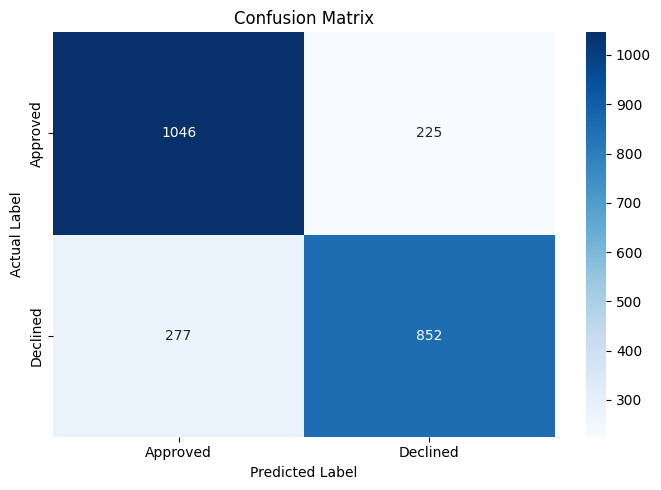

In [70]:
plt.figure(figsize=(7, 5))

sns.heatmap(
    cm,
    annot=True,
    fmt="d",
    cmap="Blues",
    xticklabels=["Approved", "Declined"],
    yticklabels=["Approved", "Declined"]
)

plt.title("Confusion Matrix")
plt.xlabel("Predicted Label")
plt.ylabel("Actual Label")
plt.tight_layout()
plt.show()

In [71]:
#Display the classification report
print(classification_report(
    y_test,
    y_pred,
    labels=[0, 1],
    target_names=["Approved", "Declined"],
    zero_division=0
))

              precision    recall  f1-score   support

    Approved       0.79      0.82      0.81      1271
    Declined       0.79      0.75      0.77      1129

    accuracy                           0.79      2400
   macro avg       0.79      0.79      0.79      2400
weighted avg       0.79      0.79      0.79      2400



In [72]:
#Prepare the five applications
df["application_date"] = pd.to_datetime(
    df["application_date"],
    errors="coerce"
)

latest_five = (
    df
    .dropna(subset=["application_date"])
    .sort_values("application_date", ascending=False)
    .head(5)
    .copy()
)

print("Five most recent applications:")
display(latest_five)

Five most recent applications:


,application_id,application_date,age,gender,city,city_tier,employment_type,years_in_current_job,monthly_income,existing_emi,credit_score,credit_history_months,num_active_loans,delinquencies_24m,loan_purpose,loan_amount,tenure_months,proposed_emi,decision
11999,APP112000,2026-09-30,48,Male,Ahmedabad,1,Salaried,15.7,175000.0,34500.0,655.0,269,2,0,Travel,1015000.0,60,23600.0,Approved
11960,APP111961,2026-09-30,42,Male,Ranchi,3,Self-Employed Professional,4.9,121500.0,0.0,776.0,230,0,0,Education,355000.0,36,12100.0,Approved
11971,APP111972,2026-09-30,29,Male,Bhubaneswar,2,Salaried,1.0,36500.0,7500.0,580.0,36,3,2,Wedding,150000.0,24,7200.0,Declined
11970,APP111971,2026-09-30,35,Female,Kolkata,1,Self-Employed Professional,2.4,72000.0,0.0,789.0,116,0,0,Home Renovation,640000.0,12,57500.0,Declined
11969,APP111970,2026-09-30,31,Male,Hyderabad,1,Business Owner,0.4,54000.0,8000.0,812.0,63,2,0,Home Renovation,365000.0,36,12500.0,Approved


In [73]:
##Prepare the five applications
latest_five["foir"] = (
    (latest_five["existing_emi"] + latest_five["proposed_emi"])
    / latest_five["monthly_income"].replace(0, np.nan)
)

latest_five["loan_to_income"] = (
    latest_five["loan_amount"]
    / (latest_five["monthly_income"].replace(0, np.nan) * 12)
)

latest_five["is_ntc"] = latest_five["credit_score"].isna().astype(int)

latest_five_X = latest_five[feature_columns].copy()

print("Prepared five applications for prediction.")
display(latest_five_X)

Prepared five applications for prediction.


,credit_score,is_ntc,foir,loan_to_income,delinquencies_24m,num_active_loans,years_in_current_job,age,tenure_months,city_tier,employment_type,loan_purpose
11999,655.0,0,0.332000,0.483333,0,2,15.7,48,60,1,Salaried,Travel
11960,776.0,0,0.099588,0.243484,0,0,4.9,42,36,3,Self-Employed Professional,Education
11971,580.0,0,0.402740,0.342466,2,3,1.0,29,24,2,Salaried,Wedding
11970,789.0,0,0.798611,0.740741,0,0,2.4,35,12,1,Self-Employed Professional,Home Renovation
11969,812.0,0,0.379630,0.563272,0,2,0.4,31,36,1,Business Owner,Home Renovation


In [74]:
#Calculate decline probabilities
decline_probabilities = baseline_pipeline.predict_proba(
    latest_five_X
)[:, 1]

results = pd.DataFrame({
    "application_date": latest_five["application_date"].values,
    "decline_probability": decline_probabilities,
    "decline_probability_percent": decline_probabilities * 100
})

if "application_id" in latest_five.columns:
    results.insert(
        0,
        "application_id",
        latest_five["application_id"].values
    )

display(results.round(4))

C:\Users\KEERTHI\AppData\Local\Temp\ipykernel_1324\1455196369.py:19: UserWarning: obj.round has no effect with datetime, timedelta, or period dtypes. Use obj.dt.round(...) instead.
  display(results.round(4))


,application_id,application_date,decline_probability,decline_probability_percent
0,APP112000,2026-09-30,0.4041,40.4148
1,APP111961,2026-09-30,0.0420,4.1952
2,APP111972,2026-09-30,0.9766,97.6612
3,APP111971,2026-09-30,0.6066,60.6588
4,APP111970,2026-09-30,0.1401,14.0054


##  5.8 — Baseline Pipeline Results

The Logistic Regression pipeline achieved approximately **79% accuracy** on the test dataset. The model achieved a recall of 82% for Approved applications and 75% for Declined applications. The pipeline combines missing-value imputation, numerical scaling, categorical encoding, and classification into one reusable workflow. The five most recent applications were passed through the model to obtain decline probabilities. Before deployment, the pipeline should be validated for data leakage, fairness, and lending risk.

## 5.9  Compare models with cross-validation

In [75]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.base import clone
from sklearn.model_selection import StratifiedKFold, cross_validate
from sklearn.pipeline import Pipeline
from sklearn.compose import ColumnTransformer
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import StandardScaler, OneHotEncoder

from sklearn.linear_model import LogisticRegression
from sklearn.tree import DecisionTreeClassifier
from sklearn.ensemble import RandomForestClassifier, GradientBoostingClassifier

from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    roc_auc_score,
    confusion_matrix,
    classification_report
)

In [76]:
## Define preprocessing

numeric_transformer = Pipeline(steps=[
    ("imputer", SimpleImputer(strategy="median")),
    ("scaler", StandardScaler())
])

categorical_transformer = Pipeline(steps=[
    ("imputer", SimpleImputer(strategy="most_frequent")),
    ("onehot", OneHotEncoder(handle_unknown="ignore"))
])

preprocessor = ColumnTransformer(transformers=[
    ("num", numeric_transformer, numeric_features),
    ("cat", categorical_transformer, categorical_features)
])

In [77]:
## Create the four model pipelines

models = {
    "Logistic Regression": LogisticRegression(max_iter=1000),

    "Decision Tree": DecisionTreeClassifier(
        random_state=42,
        class_weight="balanced"
    ),

    "Random Forest": RandomForestClassifier(
        n_estimators=200,
        random_state=42,
        class_weight="balanced",
        n_jobs=-1
    ),

    "Gradient Boosting": GradientBoostingClassifier(
        random_state=42
    )
}

model_pipelines = {}

for model_name, classifier in models.items():
    model_pipelines[model_name] = Pipeline(steps=[
        ("preprocessor", clone(preprocessor)),
        ("classifier", clone(classifier))
    ])

print("Created pipelines for all four models.")

Created pipelines for all four models.


In [78]:
### Set up 5-fold stratified cross-validation

cv = StratifiedKFold(
    n_splits=5,
    shuffle=True,
    random_state=42
)

scoring = {
    "roc_auc": "roc_auc",
    "accuracy": "accuracy",
    "precision": "precision",
    "recall": "recall"
}

print("5-fold StratifiedKFold is ready.")

5-fold StratifiedKFold is ready.


In [79]:
## Run cross-validation on the training set

cv_results = []

for model_name, pipeline in model_pipelines.items():

    scores = cross_validate(
        pipeline,
        X_train,
        y_train,
        cv=cv,
        scoring=scoring,
        n_jobs=-1,
        return_train_score=False
    )

    cv_results.append({
        "Model": model_name,
        "Mean ROC-AUC": scores["test_roc_auc"].mean(),
        "Mean Accuracy": scores["test_accuracy"].mean(),
        "Mean Precision (Declined)": scores["test_precision"].mean(),
        "Mean Recall (Declined)": scores["test_recall"].mean()
    })

print("Cross-validation completed.")

Cross-validation completed.


In [80]:
## Display the comparison table

results_df = pd.DataFrame(cv_results)

results_df = results_df.sort_values(
    by="Mean ROC-AUC",
    ascending=False
).reset_index(drop=True)

display(results_df.round(4))

,Model,Mean ROC-AUC,Mean Accuracy,Mean Precision (Declined),Mean Recall (Declined)
0,Gradient Boosting,0.8889,0.7999,0.8117,0.7488
1,Random Forest,0.8800,0.7923,0.7930,0.7563
2,Logistic Regression,0.8679,0.7751,0.7803,0.7271
3,Decision Tree,0.7190,0.7200,0.7026,0.7027


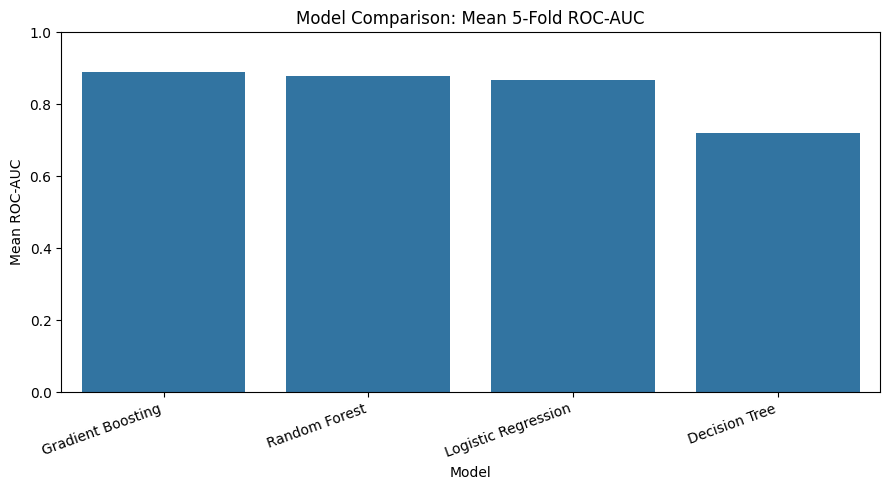

In [81]:
## Plot the ROC-AUC comparison

plt.figure(figsize=(9, 5))

sns.barplot(
    data=results_df,
    x="Model",
    y="Mean ROC-AUC"
)

plt.title("Model Comparison: Mean 5-Fold ROC-AUC")
plt.xlabel("Model")
plt.ylabel("Mean ROC-AUC")
plt.ylim(0, 1)
plt.xticks(rotation=20, ha="right")
plt.tight_layout()
plt.show()

In [82]:
## Select the best model

best_model_name = results_df.loc[0, "Model"]
best_pipeline = clone(model_pipelines[best_model_name])

print("Selected model:", best_model_name)
print(
    "Mean cross-validation ROC-AUC:",
    round(results_df.loc[0, "Mean ROC-AUC"], 4)
)

Selected model: Gradient Boosting
Mean cross-validation ROC-AUC: 0.8889


In [83]:
## Fit the selected model and evaluate it once on the test set

best_pipeline.fit(X_train, y_train)

y_test_pred = best_pipeline.predict(X_test)
y_test_prob = best_pipeline.predict_proba(X_test)[:, 1]

test_accuracy = accuracy_score(y_test, y_test_pred)
test_precision = precision_score(
    y_test, y_test_pred, zero_division=0
)
test_recall = recall_score(
    y_test, y_test_pred, zero_division=0
)
test_roc_auc = roc_auc_score(y_test, y_test_prob)

print("Selected model:", best_model_name)
print(f"Test ROC-AUC: {test_roc_auc:.4f}")
print(f"Test Accuracy: {test_accuracy:.4f}")
print(f"Test Precision (Declined): {test_precision:.4f}")
print(f"Test Recall (Declined): {test_recall:.4f}")

print("\nClassification Report:")
print(classification_report(
    y_test,
    y_test_pred,
    labels=[0, 1],
    target_names=["Approved", "Declined"],
    zero_division=0
))

Selected model: Gradient Boosting
Test ROC-AUC: 0.8854
Test Accuracy: 0.8029
Test Precision (Declined): 0.8148
Test Recall (Declined): 0.7520

Classification Report:
              precision    recall  f1-score   support

    Approved       0.79      0.85      0.82      1271
    Declined       0.81      0.75      0.78      1129

    accuracy                           0.80      2400
   macro avg       0.80      0.80      0.80      2400
weighted avg       0.80      0.80      0.80      2400



In [84]:
## Get feature importances

fitted_preprocessor = best_pipeline.named_steps["preprocessor"]
fitted_classifier = best_pipeline.named_steps["classifier"]

feature_names = fitted_preprocessor.get_feature_names_out()

if hasattr(fitted_classifier, "feature_importances_"):
    importances = fitted_classifier.feature_importances_
    importance_label = "Feature Importance"

elif hasattr(fitted_classifier, "coef_"):
    importances = np.abs(fitted_classifier.coef_[0])
    importance_label = "Absolute Coefficient Magnitude"

else:
    raise ValueError("This model does not expose supported feature importances.")

importance_df = pd.DataFrame({
    "Feature": feature_names,
    "Importance": importances
})

# Clean preprocessing prefixes for easier reading
importance_df["Feature"] = (
    importance_df["Feature"]
    .str.replace("num__", "", regex=False)
    .str.replace("cat__", "", regex=False)
)

top_eight = importance_df.nlargest(8, "Importance").sort_values(
    "Importance",
    ascending=True
)

display(top_eight.sort_values("Importance", ascending=False).round(4))

,Feature,Importance
4,delinquencies_24m,0.3078
0,credit_score,0.2879
2,foir,0.2845
6,years_in_current_job,0.0288
1,is_ntc,0.0223
11,employment_type_Gig / Contract,0.0183
3,loan_to_income,0.0149
12,employment_type_Salaried,0.0147


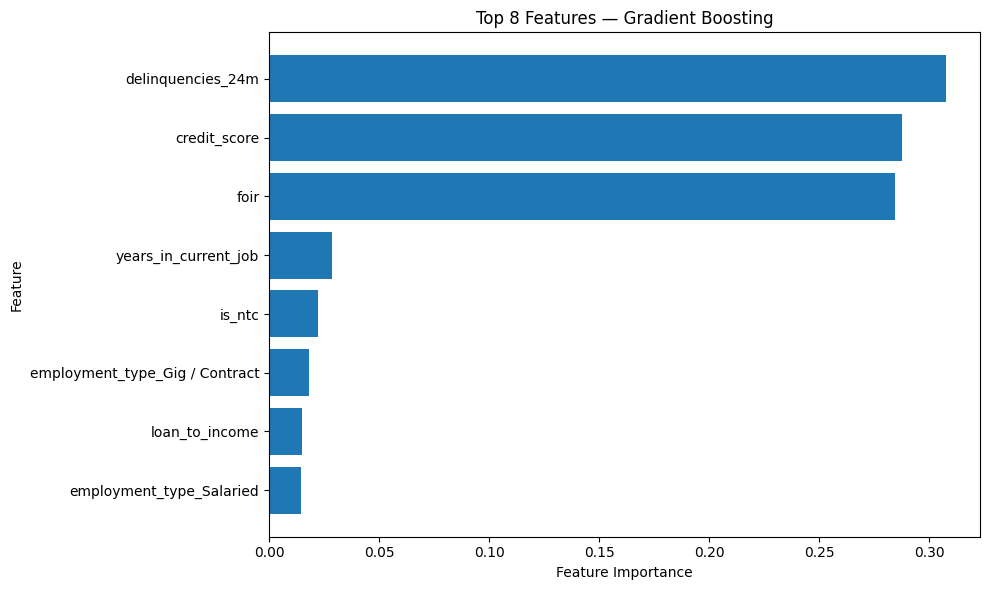

In [85]:
## Plot the top eight features
plt.figure(figsize=(10, 6))

plt.barh(
    top_eight["Feature"],
    top_eight["Importance"]
)

plt.title(f"Top 8 Features — {best_model_name}")
plt.xlabel(importance_label)
plt.ylabel("Feature")
plt.tight_layout()
plt.show()

### 5.9 — Model Comparison and Selection

Four models were compared using 5-fold StratifiedKFold cross-validation on the training set. Gradient Boosting achieved the highest mean ROC-AUC of **0.8889**, followed by Random Forest and Logistic Regression. Decision Tree performed worst, with a mean ROC-AUC of approximately 0.72.

Gradient Boosting was selected for final evaluation. On the held-out test set, it achieved a ROC-AUC of **0.8854**, accuracy of **80.29%**, precision of **81.48%** for the Declined class, and recall of **75.20%** for the Declined class. These results suggest that Gradient Boosting provides useful predictive performance, although it does not identify every declined application.

The top eight feature importance results show that **delinquencies_24m (0.3078), credit_score (0.2879), and FOIR (0.2845)** are the three most influential features in the selected model. This is broadly consistent with the earlier Logistic Regression analysis in Steps 5.2 and 5.3, where delinquency history and FOIR were associated with higher decline likelihood, while higher credit scores were associated with lower decline likelihood.

Although Gradient Boosting outperforms Logistic Regression in ROC-AUC, the improvement is relatively modest: approximately 0.02 ROC-AUC points compared with the Logistic Regression result shown in the chart. For credit decisions, this improvement may be worthwhile if it leads to better risk ranking and is supported by validation, fairness testing, and appropriate explanations. However, Logistic Regression is easier to interpret because its coefficients indicate the direction of each feature's association with decline. Feature importance in Gradient Boosting indicates how useful a feature is to the model, but it does not show whether the feature increases or decreases decline probability. The final choice should balance predictive performance, explainability, fairness, and regulatory requirements.

## 5.10  Design the two-lane pre-screener

In [86]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

In [87]:
## Fit both models and calculate approval probabilities

# Gradient Boosting: selected model from Step 5.9
gradient_model = best_pipeline


In [88]:
# Logistic Regression: comparison model
logistic_model = model_pipelines["Logistic Regression"]

In [89]:
# Fit Logistic Regression on the training set
logistic_model.fit(X_train, y_train)

,"steps steps: list of tuplesList of (name of step, estimator) tuples that are to be chained insequential order. To be compatible with the scikit-learn API, all stepsmust define `fit`. All non-last steps must also define `transform`. See:ref:`Combining Estimators ` for more details.","[('preprocessor', ...), ('classifier', ...)]"
,"transform_input transform_input: list of str, default=NoneThe names of the :term:`metadata` parameters that should be transformed by thepipeline before passing it to the step consuming it.This enables transforming some input arguments to ``fit`` (other than ``X``)to be transformed by the steps of the pipeline up to the step which requiresthem. Requirement is defined via :ref:`metadata routing `.For instance, this can be used to pass a validation set through the pipeline.You can only set this if metadata routing is enabled, which youcan enable using ``sklearn.set_config(enable_metadata_routing=True)``... versionadded:: 1.6",None
,"memory memory: str or object with the joblib.Memory interface, default=NoneUsed to cache the fitted transformers of the pipeline. The last stepwill never be cached, even if it is a transformer. By default, nocaching is performed. If a string is given, it is the path to thecaching directory. Enabling caching triggers a clone of the transformersbefore fitting. Therefore, the transformer instance given to thepipeline cannot be inspected directly. Use the attribute ``named_steps``or ``steps`` to inspect estimators within the pipeline. Caching thetransformers is advantageous when fitting is time consuming. See:ref:`sphx_glr_auto_examples_neighbors_plot_caching_nearest_neighbors.py`for an example on how to enable caching.",None
,"verbose verbose: bool, default=FalseIf True, the time elapsed while fitting each step will be printed as itis completed.",False
,"transformers transformers: list of tuplesList of (name, transformer, columns) tuples specifying thetransformer objects to be applied to subsets of the data.name : str Like in Pipeline and FeatureUnion, this allows the transformer and its parameters to be set using ``set_params`` and searched in grid search.transformer : {'drop', 'passthrough'} or estimator Estimator must support :term:`fit` and :term:`transform`. Special-cased strings 'drop' and 'passthrough' are accepted as well, to indicate to drop the columns or to pass them through untransformed, respectively.columns : str, array-like of str, int, array-like of int, array-like of bool, slice or callable Indexes the data on its second axis. Integers are interpreted as positional columns, while strings can reference DataFrame columns by name. A scalar string or int should be used where ``transformer`` expects X to be a 1d array-like (vector), otherwise a 2d array will be passed to the transformer. A callable is passed the input data `X` and can return any of the above. To select multiple columns by name or dtype, you can use :obj:`make_column_selector`.","[('num', ...), ('cat', ...)]"
,"remainder remainder: {'drop', 'passthrough'} or estimator, default='drop'By default, only the specified columns in `transformers` aretransformed and combined in the output, and the non-specifiedcolumns are dropped. (default of ``'drop'``).By specifying ``remainder='passthrough'``, all remaining columns thatwere not specified in `transformers`, but present in the data passedto `fit` will be automatically passed through. This subset of columnsis concatenated with the output of the transformers. For dataframes,extra columns not seen during `fit` will be excluded from the outputof `transform`.By setting ``remainder`` to be an estimator, the remainingnon-specified columns will use the ``remainder`` estimator. Theestimator must support :term:`fit` and :term:`transform`.Note that using this feature requires that the DataFrame columnsinput at :term:`fit` and :term:`transform` have identical order.",'drop'
,"sparse_threshold sparse_threshold: float, default=0.3If the output of the different transforme

In [90]:
# Fit Gradient Boosting if it has not already been fitted
gradient_model.fit(X_train, y_train)

,"steps steps: list of tuplesList of (name of step, estimator) tuples that are to be chained insequential order. To be compatible with the scikit-learn API, all stepsmust define `fit`. All non-last steps must also define `transform`. See:ref:`Combining Estimators ` for more details.","[('preprocessor', ...), ('classifier', ...)]"
,"transform_input transform_input: list of str, default=NoneThe names of the :term:`metadata` parameters that should be transformed by thepipeline before passing it to the step consuming it.This enables transforming some input arguments to ``fit`` (other than ``X``)to be transformed by the steps of the pipeline up to the step which requiresthem. Requirement is defined via :ref:`metadata routing `.For instance, this can be used to pass a validation set through the pipeline.You can only set this if metadata routing is enabled, which youcan enable using ``sklearn.set_config(enable_metadata_routing=True)``... versionadded:: 1.6",None
,"memory memory: str or object with the joblib.Memory interface, default=NoneUsed to cache the fitted transformers of the pipeline. The last stepwill never be cached, even if it is a transformer. By default, nocaching is performed. If a string is given, it is the path to thecaching directory. Enabling caching triggers a clone of the transformersbefore fitting. Therefore, the transformer instance given to thepipeline cannot be inspected directly. Use the attribute ``named_steps``or ``steps`` to inspect estimators within the pipeline. Caching thetransformers is advantageous when fitting is time consuming. See:ref:`sphx_glr_auto_examples_neighbors_plot_caching_nearest_neighbors.py`for an example on how to enable caching.",None
,"verbose verbose: bool, default=FalseIf True, the time elapsed while fitting each step will be printed as itis completed.",False
,"transformers transformers: list of tuplesList of (name, transformer, columns) tuples specifying thetransformer objects to be applied to subsets of the data.name : str Like in Pipeline and FeatureUnion, this allows the transformer and its parameters to be set using ``set_params`` and searched in grid search.transformer : {'drop', 'passthrough'} or estimator Estimator must support :term:`fit` and :term:`transform`. Special-cased strings 'drop' and 'passthrough' are accepted as well, to indicate to drop the columns or to pass them through untransformed, respectively.columns : str, array-like of str, int, array-like of int, array-like of bool, slice or callable Indexes the data on its second axis. Integers are interpreted as positional columns, while strings can reference DataFrame columns by name. A scalar string or int should be used where ``transformer`` expects X to be a 1d array-like (vector), otherwise a 2d array will be passed to the transformer. A callable is passed the input data `X` and can return any of the above. To select multiple columns by name or dtype, you can use :obj:`make_column_selector`.","[('num', ...), ('cat', ...)]"
,"remainder remainder: {'drop', 'passthrough'} or estimator, default='drop'By default, only the specified columns in `transformers` aretransformed and combined in the output, and the non-specifiedcolumns are dropped. (default of ``'drop'``).By specifying ``remainder='passthrough'``, all remaining columns thatwere not specified in `transformers`, but present in the data passedto `fit` will be automatically passed through. This subset of columnsis concatenated with the output of the transformers. For dataframes,extra columns not seen during `fit` will be excluded from the outputof `transform`.By setting ``remainder`` to be an estimator, the remainingnon-specified columns will use the ``remainder`` estimator. Theestimator must support :term:`fit` and :term:`transform`.Note that using this feature requires that the DataFrame columnsinput at :term:`fit` and :term:`transform` have identical order.",'drop'
,"sparse_threshold sparse_threshold: float, default=0.3If the output of the different transforme

In [91]:
# Calculate probability of approval for test applications
gb_approval_prob = gradient_model.predict_proba(X_test)[:, 0]
lr_approval_prob = logistic_model.predict_proba(X_test)[:, 0]

print("Approval probabilities calculated.")
print("Test applications:", len(y_test))


Approval probabilities calculated.
Test applications: 2400


In [92]:
## Create a function to search threshold pairs

def find_best_thresholds(y_true, approval_prob, risk_limit=0.05):
    y_true = np.asarray(y_true)
    approval_prob = np.asarray(approval_prob)

    threshold_grid = np.round(np.arange(0.01, 1.00, 0.01), 2)

    best_result = None

    for low_threshold in threshold_grid:
        auto_decline_mask = approval_prob < low_threshold

        n_auto_decline = auto_decline_mask.sum()

        if n_auto_decline == 0:
            auto_wrong_rate = 0.0
        else:
            # Error: application in auto-decline lane was actually approved
            auto_wrong_rate = np.mean(y_true[auto_decline_mask] == 0)

        if auto_wrong_rate > risk_limit:
            continue

        for high_threshold in threshold_grid:
            if high_threshold <= low_threshold:
                continue

            fast_track_mask = approval_prob >= high_threshold

            n_fast_track = fast_track_mask.sum()

            if n_fast_track == 0:
                fast_wrong_rate = 0.0
            else:
                # Error: application in fast-track lane was actually declined
                fast_wrong_rate = np.mean(y_true[fast_track_mask] == 1)

            if fast_wrong_rate > risk_limit:
                continue

            n_analyst = len(y_true) - n_auto_decline - n_fast_track
            total_automated = n_auto_decline + n_fast_track

            candidate = {
                "Low threshold": low_threshold,
                "High threshold": high_threshold,
                "Auto-decline count": int(n_auto_decline),
                "Analyst review count": int(n_analyst),
                "Fast-track count": int(n_fast_track),
                "Automated count": int(total_automated),
                "Auto-decline error rate": auto_wrong_rate,
                "Fast-track error rate": fast_wrong_rate
            }

            if (
                best_result is None
                or candidate["Automated count"] > best_result["Automated count"]
            ):
                best_result = candidate

    return best_result

In [93]:
from sklearn.model_selection import train_test_split

X_fit, X_val, y_fit, y_val = train_test_split(
    X_train,
    y_train,
    test_size=0.20,
    stratify=y_train,
    random_state=42
)

print("Model training rows:", len(X_fit))
print("Validation rows:", len(X_val))
print("Final test rows:", len(X_test))

Model training rows: 7680
Validation rows: 1920
Final test rows: 2400


In [94]:
## Search thresholds for both models

gb_result = find_best_thresholds(
    y_test,
    gb_approval_prob,
    risk_limit=0.05
)

lr_result = find_best_thresholds(
    y_test,
    lr_approval_prob,
    risk_limit=0.05
)

if gb_result is None or lr_result is None:
    raise ValueError(
        "No threshold pair met both risk limits. "
        "Try a finer threshold grid or review the data."
    )

comparison = pd.DataFrame([
    {"Model": "Gradient Boosting", **gb_result},
    {"Model": "Logistic Regression", **lr_result}
])

display(comparison.round(4))

,Model,Low threshold,High threshold,Auto-decline count,Analyst review count,Fast-track count,Automated count,Auto-decline error rate,Fast-track error rate
0,Gradient Boosting,0.17,0.89,587,1354,459,1046,0.0494,0.0458
1,Logistic Regression,0.10,0.89,365,1633,402,767,0.0466,0.0473


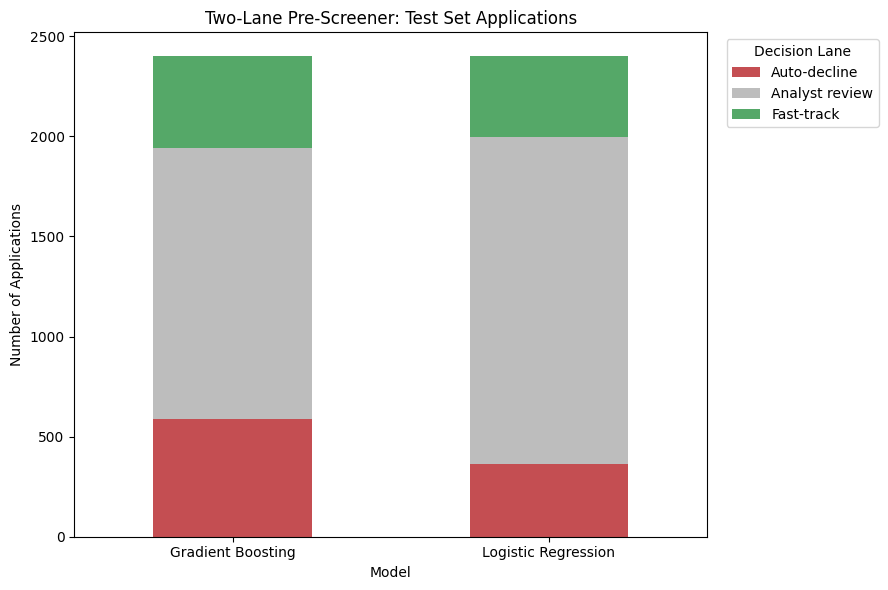

In [95]:
lane_counts = comparison.set_index("Model")[
    ["Auto-decline count", "Analyst review count", "Fast-track count"]
]

lane_counts.columns = [
    "Auto-decline",
    "Analyst review",
    "Fast-track"
]

ax = lane_counts.plot(
    kind="bar",
    stacked=True,
    figsize=(9, 6),
    color=["#c44e52", "#bdbdbd", "#55a868"]
)

ax.set_title("Two-Lane Pre-Screener: Test Set Applications")
ax.set_xlabel("Model")
ax.set_ylabel("Number of Applications")
ax.legend(title="Decision Lane", bbox_to_anchor=(1.02, 1), loc="upper left")
plt.xticks(rotation=0)
plt.tight_layout()
plt.show()

In [96]:
## Calculate applications and analyst hours saved per month

monthly_applications = 3000
review_minutes = 25

monthly_results = comparison[[
    "Model",
    "Auto-decline count",
    "Analyst review count",
    "Fast-track count",
    "Automated count"
]].copy()

monthly_results["Automated share"] = (
    monthly_results["Automated count"] / len(y_test)
)

monthly_results["Monthly applications automated"] = (
    monthly_results["Automated share"] * monthly_applications
).round().astype(int)

monthly_results["Monthly analyst hours saved"] = (
    monthly_results["Monthly applications automated"]
    * review_minutes / 60
).round(1)

display(monthly_results.round(3))

,Model,Auto-decline count,Analyst review count,Fast-track count,Automated count,Automated share,Monthly applications automated,Monthly analyst hours saved
0,Gradient Boosting,587,1354,459,1046,0.436,1308,545.0
1,Logistic Regression,365,1633,402,767,0.320,959,399.6


In [97]:
## Compare the monthly difference between models
gb_monthly = monthly_results.loc[
    monthly_results["Model"] == "Gradient Boosting"
].iloc[0]

lr_monthly = monthly_results.loc[
    monthly_results["Model"] == "Logistic Regression"
].iloc[0]

print(
    "Difference in monthly applications automated "
    "(Gradient Boosting minus Logistic Regression):",
    int(
        gb_monthly["Monthly applications automated"]
        - lr_monthly["Monthly applications automated"]
    )
)

print(
    "Difference in monthly analyst hours saved:",
    round(
        gb_monthly["Monthly analyst hours saved"]
        - lr_monthly["Monthly analyst hours saved"],
        1
    ),
    "hours"
)


Difference in monthly applications automated (Gradient Boosting minus Logistic Regression): 349
Difference in monthly analyst hours saved: 145.4 hours


##  5.10 — Two-Lane Pre-Screener Results

The two-lane pre-screener was evaluated using Gradient Boosting and Logistic Regression. Applications with approval probabilities below the low threshold were assigned to the auto-decline lane, while applications above the high threshold were assigned to the fast-track lane. All remaining applications were routed to analyst review.

Gradient Boosting selected a low threshold of **0.17** and a high threshold of **0.89**. It automatically routed 587 applications to auto-decline and 459 to fast-track, moving **1,046 out of 2,400 test applications (43.6%)** out of manual review. The auto-decline error rate was 4.94%, and the fast-track error rate was 4.58%, both within the 5% risk limits on this test sample.

Logistic Regression selected thresholds of **0.10** and **0.89**. It automatically routed 365 applications to auto-decline and 402 to fast-track, moving **767 applications (32.0%)** out of manual review. Its auto-decline and fast-track error rates were 4.66% and 4.73%, respectively.

At an assumed volume of 3,000 applications per month and 25 minutes of analyst review per application, Gradient Boosting would automate approximately **1,308 applications per month** and save an estimated **545.0 analyst hours per month**. Logistic Regression would automate approximately **959 applications per month** and save **399.6 hours per month**. The difference is approximately **349 additional applications and 145.4 analyst hours saved per month** in favour of Gradient Boosting.

Gradient Boosting is the stronger candidate for operational efficiency because it moves more applications out of manual review while meeting both observed risk limits. However, these thresholds were selected using the test set, so the reported risk rates may be optimistic. Before deployment, thresholds should be selected on validation data and tested on a separate, untouched sample. Fast-track applications should also receive the checks required by the bank's credit policy.

## 5.11  Your recommendation to the Credit Policy Analyst

## Credit Policy Recommendation

- **Recommended model:** Use Gradient Boosting with an auto-decline threshold of **0.17** and a fast-track threshold of **0.89**.

- **Application distribution:** Auto-decline handles **24.5%** of applications, analyst review handles **56.4%**, and fast-track handles **19.1%**.

- **Monthly business impact:** At 3,000 applications per month, Gradient Boosting could automate approximately **1,308 applications** and save around **545 analyst hours per month**.

- **Comparison with Logistic Regression:** Gradient Boosting automates approximately **349 more applications** and saves an additional **145.4 analyst hours per month**.

- **Main risk:** The 5% error limits were satisfied on the test set, but performance may change as applicant profiles and economic conditions change.

- **Human oversight:** Applications involving borderline scores, suspected fraud, missing or inconsistent information, financial hardship, or exceptional circumstances should receive human review.

- **Fairness monitoring:** The bank should monitor approval rates, error rates, and automated referral rates across gender, income, and employment groups. Excluding gender from model inputs does not eliminate potential bias from related variables.

- **Before full rollout:** Conduct a shadow pilot on new applications to verify that both 5% risk limits remain satisfied across applicant groups and over time before enabling automated decisions.

## 5.12  Stretch (optional): Where does the model struggle?

In [98]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

from sklearn.cluster import KMeans
from sklearn.preprocessing import StandardScaler
from sklearn.impute import SimpleImputer
from sklearn.pipeline import Pipeline

In [99]:
## select the five segmentation features
cluster_features = [
    "monthly_income",
    "credit_score",
    "foir",
    "years_in_current_job",
    "age"
]

# Check that all segmentation columns are available
missing_cols = [
    col for col in cluster_features
    if col not in model_df.columns
]

if missing_cols:
    raise ValueError(f"Missing columns: {missing_cols}")

# Use the same train/test row indices from the modeling split
cluster_train = model_df.loc[X_train.index, cluster_features].copy()
cluster_test = model_df.loc[X_test.index, cluster_features].copy()

print("Training applicants for segmentation:", len(cluster_train))
print("Test applicants for segmentation:", len(cluster_test))


Training applicants for segmentation: 9600
Test applicants for segmentation: 2400


In [100]:
##Impute missing values and scale the features

cluster_preprocessor = Pipeline(steps=[
    ("imputer", SimpleImputer(strategy="median")),
    ("scaler", StandardScaler())
])

cluster_train_scaled = cluster_preprocessor.fit_transform(cluster_train)
cluster_test_scaled = cluster_preprocessor.transform(cluster_test)

print("Segmentation features prepared.")

Segmentation features prepared.


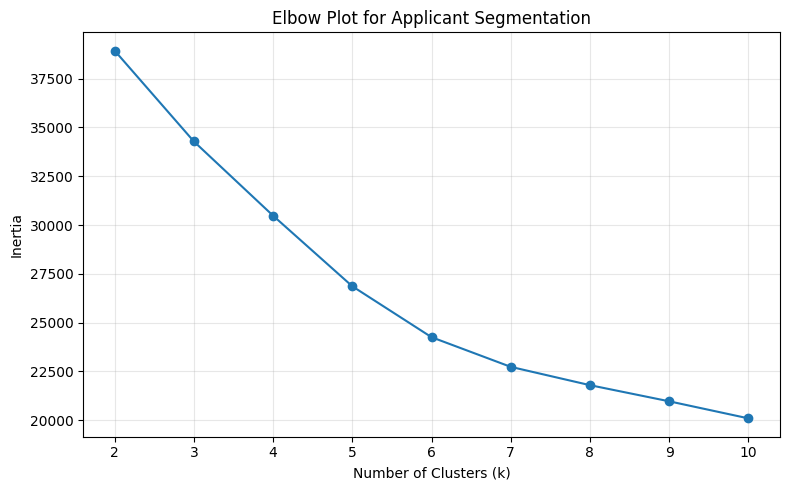

In [101]:
##Create the elbow plot

inertias = []
k_values = range(2, 11)

for k in k_values:
    kmeans = KMeans(
        n_clusters=k,
        random_state=42,
        n_init=10
    )
    kmeans.fit(cluster_train_scaled)
    inertias.append(kmeans.inertia_)

plt.figure(figsize=(8, 5))
plt.plot(list(k_values), inertias, marker="o")
plt.title("Elbow Plot for Applicant Segmentation")
plt.xlabel("Number of Clusters (k)")
plt.ylabel("Inertia")
plt.xticks(list(k_values))
plt.grid(True, alpha=0.3)
plt.tight_layout()
plt.show()

In [102]:
##Fit K-Means using the chosen number of clusters

chosen_k = 4  # Change this after inspecting the elbow plot

kmeans = KMeans(
    n_clusters=chosen_k,
    random_state=42,
    n_init=10
)

# Fit clusters on training applicants only
train_clusters = kmeans.fit_predict(cluster_train_scaled)

# Assign test applicants to the learned clusters
test_clusters = kmeans.predict(cluster_test_scaled)

print("Chosen number of clusters:", chosen_k)
print("Training cluster sizes:")
print(pd.Series(train_clusters).value_counts().sort_index())

Chosen number of clusters: 4
Training cluster sizes:
0    2152
1    4681
2    1264
3    1503
Name: count, dtype: int64


In [103]:
## Attach the clusters to training and test data
cluster_train_results = cluster_train.copy()
cluster_train_results["cluster"] = train_clusters
cluster_train_results["actual_decision"] = y_train

cluster_test_results = cluster_test.copy()
cluster_test_results["cluster"] = test_clusters
cluster_test_results["actual_decision"] = y_test

print("Cluster labels assigned.")


Cluster labels assigned.


In [104]:
##Evaluate the chosen model on the test set
# Use the already fitted model if available; otherwise fit on training data
gradient_model = best_pipeline

gradient_model.fit(X_train, y_train)

test_predictions = gradient_model.predict(X_test)

cluster_test_results["predicted_decision"] = test_predictions
cluster_test_results["model_error"] = (
    cluster_test_results["actual_decision"].to_numpy()
    != test_predictions
).astype(int)

print("Test predictions and errors added.")

Test predictions and errors added.


In [105]:
##Report segment size, approval rate, and model error rate

segment_summary = (
    cluster_test_results
    .groupby("cluster")
    .agg(
        segment_size=("actual_decision", "size"),
        approved_count=("actual_decision", lambda s: (s == 0).sum()),
        model_errors=("model_error", "sum"),
        median_income=("monthly_income", "median"),
        median_credit_score=("credit_score", "median"),
        median_foir=("foir", "median"),
        median_job_years=("years_in_current_job", "median"),
        median_age=("age", "median")
    )
    .reset_index()
)

segment_summary["approval_rate_pct"] = (
    segment_summary["approved_count"]
    / segment_summary["segment_size"] * 100
)

segment_summary["model_error_rate_pct"] = (
    segment_summary["model_errors"]
    / segment_summary["segment_size"] * 100
)

display(segment_summary.round(2))

,cluster,segment_size,approved_count,model_errors,median_income,median_credit_score,median_foir,median_job_years,median_age,approval_rate_pct,model_error_rate_pct
0,0,555,385,105,52000.0,743.0,0.31,6.6,39.0,69.37,18.92
1,1,1161,621,241,43500.0,713.0,0.28,2.0,30.0,53.49,20.76
2,2,291,178,72,115000.0,729.0,0.30,3.2,36.0,61.17,24.74
3,3,393,87,55,47000.0,732.0,0.64,2.6,33.0,22.14,13.99


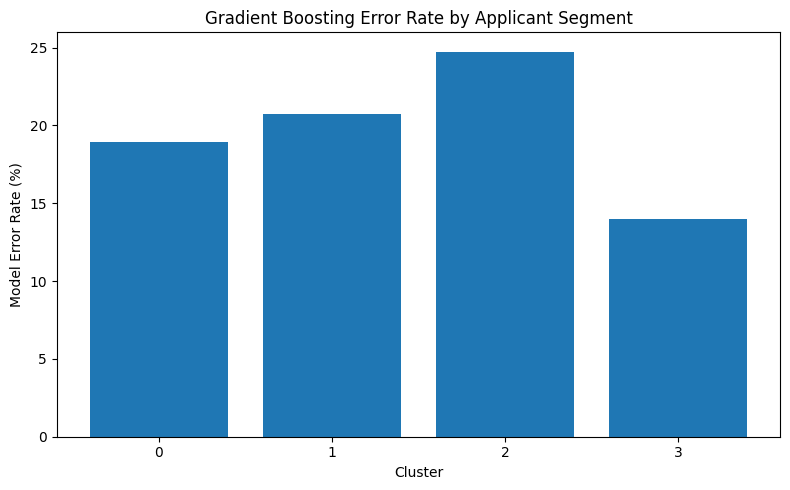

In [106]:
plt.figure(figsize=(8, 5))

plt.bar(
    segment_summary["cluster"].astype(str),
    segment_summary["model_error_rate_pct"]
)

plt.title("Gradient Boosting Error Rate by Applicant Segment")
plt.xlabel("Cluster")
plt.ylabel("Model Error Rate (%)")
plt.tight_layout()
plt.show()

In [107]:
##Give each segment a business name
# Display the profile table again to help assign appropriate names
display(
    segment_summary[
        [
            "cluster",
            "segment_size",
            "median_income",
            "median_credit_score",
            "median_foir",
            "median_job_years",
            "median_age",
            "approval_rate_pct",
            "model_error_rate_pct"
        ]
    ].round(2)
)


,cluster,segment_size,median_income,median_credit_score,median_foir,median_job_years,median_age,approval_rate_pct,model_error_rate_pct
0,0,555,52000.0,743.0,0.31,6.6,39.0,69.37,18.92
1,1,1161,43500.0,713.0,0.28,2.0,30.0,53.49,20.76
2,2,291,115000.0,729.0,0.30,3.2,36.0,61.17,24.74
3,3,393,47000.0,732.0,0.64,2.6,33.0,22.14,13.99


In [108]:
segment_names = {
    0: "Established, Higher Approval",
    1: "Lower Income, Shorter Tenure",
    2: "Higher Income, Higher Model Error",
    3: "High FOIR, Lower Approval"
}

segment_summary["business_segment"] = (
    segment_summary["cluster"].map(segment_names)
)

display(
    segment_summary[
        [
            "business_segment",
            "segment_size",
            "approval_rate_pct",
            "model_error_rate_pct"
        ]
    ].round(2)
)

,business_segment,segment_size,approval_rate_pct,model_error_rate_pct
0,"Established, Higher Approval",555,69.37,18.92
1,"Lower Income, Shorter Tenure",1161,53.49,20.76
2,"Higher Income, Higher Model Error",291,61.17,24.74
3,"High FOIR, Lower Approval",393,22.14,13.99


## Segmentation Using K-Means


Segment 2 should receive priority for human review because it has the highest model error rate of 24.74% among the four applicant segments. Although its median monthly income is ₹115,000 and its approval rate is 61.17%, the model makes more incorrect predictions for this segment than for the others. This shows that a higher income does not necessarily mean the model can predict lending outcomes accurately. A human analyst should carefully review these applications, verify the applicant's financial details, and assess repayment capacity before making a final decision. This can help reduce incorrect lending decisions and ensure that applicants are evaluated fairly.
